# CM3070 Deep Learning Breast Cancer Detection

This notebook prepares the CBIS-DDSM dataset, performs basic exploratory data analysis, creates TensorFlow image generators, trains a baseline CNN model, and evaluates the model using accuracy, precision, recall, F1-score, confusion matrix, ROC curve, and AUC.

## 1. Setup and Library Imports

In [ ]:
# Connect Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Standard libraries
import os
from pathlib import Path

# Data processing
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
from PIL import Image

# Dataset splitting
from sklearn.model_selection import train_test_split

# Evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, BatchNormalization,
    Flatten, Dense, Dropout)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow version:', tf.__version__)
print('GPU available:', tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Define Dataset Paths

In [ ]:
# Main dataset location in Google Drive
dataset_path = '/content/drive/MyDrive/CM3070/CBIS-DDSM'
jpeg_path = os.path.join(dataset_path, 'jpeg')
csv_path = os.path.join(dataset_path, 'csv')

print('Dataset folder:', os.listdir(dataset_path))
print('CSV files:', os.listdir(csv_path))
print('Number of top-level JPEG folders:', len(os.listdir(jpeg_path)))

Dataset folder: ['jpeg', 'csv']
CSV files: ['mass_case_description_train_set.csv', 'calc_case_description_train_set.csv', 'dicom_info.csv', 'calc_case_description_test_set.csv', 'meta.csv', 'mass_case_description_test_set.csv']
Number of top-level JPEG folders: 6774


## 3. Load Metadata CSV Files

In [ ]:
mass_train = pd.read_csv(os.path.join(csv_path, 'mass_case_description_train_set.csv'))
mass_test = pd.read_csv(os.path.join(csv_path, 'mass_case_description_test_set.csv'))

calc_train = pd.read_csv(os.path.join(csv_path, 'calc_case_description_train_set.csv'))
calc_test = pd.read_csv(os.path.join(csv_path, 'calc_case_description_test_set.csv'))

dicom_info = pd.read_csv(os.path.join(csv_path, 'dicom_info.csv'))
meta = pd.read_csv(os.path.join(csv_path, 'meta.csv'))

print('Mass train:', mass_train.shape)
print('Mass test:', mass_test.shape)
print('Calc train:', calc_train.shape)
print('Calc test:', calc_test.shape)
print('DICOM info:', dicom_info.shape)
print('Meta:', meta.shape)

Mass train: (1318, 14)
Mass test: (378, 14)
Calc train: (1546, 14)
Calc test: (326, 14)
DICOM info: (10237, 38)
Meta: (6775, 9)


In [ ]:
# Preview the main case-description file
mass_train.head()

,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....


## 4. Exploratory Data Analysis (EDA)

In [ ]:
# Check the pathology label distribution in mass and calcification cases
print('Mass train pathology distribution:')
print(mass_train['pathology'].value_counts())

print('Calcification train pathology distribution:')
print(calc_train['pathology'].value_counts())

Mass train pathology distribution:
pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64
Calcification train pathology distribution:
pathology
MALIGNANT                  544
BENIGN                     528
BENIGN_WITHOUT_CALLBACK    474
Name: count, dtype: int64


In [ ]:
# Add lesion type and original split information
mass_train['lesion_type'] = 'mass'
mass_test['lesion_type'] = 'mass'
calc_train['lesion_type'] = 'calcification'
calc_test['lesion_type'] = 'calcification'

mass_train['split'] = 'train'
mass_test['split'] = 'test'
calc_train['split'] = 'train'
calc_test['split'] = 'test'

# Combine all case-description files
all_cases = pd.concat(
    [mass_train, mass_test, calc_train, calc_test],
    axis=0,
    ignore_index=True
)

print('Combined dataset shape:', all_cases.shape)
all_cases.head()

Combined dataset shape: (3568, 19)


,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path,lesion_type,split,breast density,calc type,calc distribution
0,P_00001,3.0,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,mass,train,NaN,NaN,NaN
1,P_00001,3.0,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,mass,train,NaN,NaN,NaN
2,P_00004,3.0,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,mass,train,NaN,NaN,NaN
3,P_00004,3.0,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,mass,train,NaN,NaN,NaN
4,P_00004,3.0,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,mass,train,NaN,NaN,NaN


In [ ]:
# Convert pathology into binary labels
# 0 = Benign, 1 = Malignant
all_cases['label'] = all_cases['pathology'].map({
    'MALIGNANT': 1,
    'BENIGN': 0,
    'BENIGN_WITHOUT_CALLBACK': 0
})

print(all_cases['label'].value_counts())
print(all_cases[['pathology', 'label']].drop_duplicates())

label
0    2111
1    1457
Name: count, dtype: int64
                  pathology  label
0                 MALIGNANT      1
2                    BENIGN      0
24  BENIGN_WITHOUT_CALLBACK      0


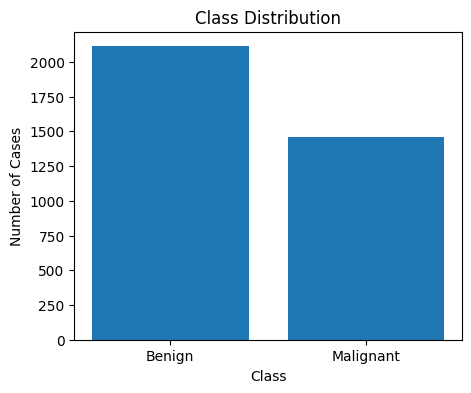

In [ ]:
# Plot class distribution
label_counts = all_cases['label'].value_counts().sort_index()

plt.figure(figsize=(5, 4))
plt.bar(['Benign', 'Malignant'], label_counts)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of Cases')
plt.show()

In [ ]:
# Check available image types in dicom_info.csv
print(dicom_info['SeriesDescription'].value_counts())

SeriesDescription
cropped images           3567
ROI mask images          3247
full mammogram images    2857
Name: count, dtype: int64


## 5. Match Labels to Full Mammogram Images

In [ ]:
# Use only full mammogram images for this classification prototype
full_mammo = dicom_info[dicom_info['SeriesDescription'] == 'full mammogram images'].copy()

print('Full mammogram records:', full_mammo.shape)
full_mammo[['PatientID', 'SeriesDescription', 'image_path']].head()

Full mammogram records: (2857, 38)


,PatientID,SeriesDescription,image_path
1,Mass-Training_P_01754_RIGHT_CC,full mammogram images,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...
2,Calc-Training_P_00232_RIGHT_CC,full mammogram images,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...
11,Mass-Training_P_01206_RIGHT_MLO,full mammogram images,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396...
12,Calc-Training_P_00506_RIGHT_MLO,full mammogram images,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.749566...
15,Calc-Training_P_01823_RIGHT_CC,full mammogram images,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.987658...


In [ ]:
# Create full Google Drive image paths
# dicom_info['image_path'] already starts with CBIS-DDSM/jpeg/...
base_path = '/content/drive/MyDrive/CM3070'

full_mammo['full_image_path'] = full_mammo['image_path'].apply(
    lambda x: os.path.join(base_path, x)
)

# Confirm that the image files exist
full_mammo['path_exists'] = full_mammo['full_image_path'].apply(os.path.exists)
print(full_mammo['path_exists'].value_counts())

path_exists
True    2857
Name: count, dtype: int64


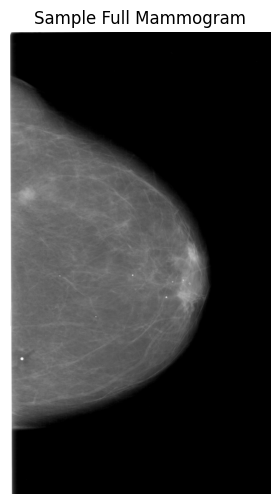

In [ ]:
# Display one sample full mammogram
sample_path = full_mammo[full_mammo['path_exists'] == True]['full_image_path'].iloc[0]
img = Image.open(sample_path)

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.title('Sample Full Mammogram')
plt.show()

In [ ]:
# Extract matching IDs from the case-description image path
all_cases['match_id'] = all_cases['image file path'].apply(lambda x: str(x).split('/')[0])
full_mammo['match_id'] = full_mammo['PatientID']

# Merge case labels with full mammogram image paths
training_data = pd.merge(
    all_cases,
    full_mammo[['match_id', 'full_image_path']],
    on='match_id',
    how='inner'
)

print('Matched training data shape:', training_data.shape)
training_data[['match_id', 'pathology', 'label', 'full_image_path']].head()

Matched training data shape: (3286, 22)


,match_id,pathology,label,full_image_path
0,Mass-Training_P_00001_LEFT_CC,MALIGNANT,1,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...
1,Mass-Training_P_00001_LEFT_MLO,MALIGNANT,1,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...
2,Mass-Training_P_00004_LEFT_CC,BENIGN,0,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...
3,Mass-Training_P_00004_LEFT_MLO,BENIGN,0,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...
4,Mass-Training_P_00004_RIGHT_MLO,BENIGN,0,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...


In [ ]:
# Verify matched labels and image paths
print('Label distribution after matching:')
print(training_data['label'].value_counts())

print('Image path check:')
print(training_data['full_image_path'].apply(os.path.exists).value_counts())

Label distribution after matching:
label
0    1931
1    1355
Name: count, dtype: int64
Image path check:
full_image_path
True    3286
Name: count, dtype: int64


## 6. Prepare Final Dataset and Split Data

In [ ]:
# Keep the columns needed for model training and analysis
final_data = training_data[
    ['match_id', 'full_image_path', 'label', 'pathology', 'lesion_type', 'split']
].copy()

final_data = final_data.rename(columns={
    'full_image_path': 'image_path'
})

# Extract the actual CBIS-DDSM patient identifier (e.g. P_00001)
final_data['patient_id'] = final_data['match_id'].str.extract(
    r'(P_\d+)'
)

print('Final dataset shape:', final_data.shape)
print('Unique patients:', final_data['patient_id'].nunique())

print('\nExample patient IDs:')
print(
    final_data[
        ['match_id', 'patient_id']
    ].drop_duplicates().head(10)
)

Final dataset shape: (3286, 7)
Unique patients: 1460

Example patient IDs:
                          match_id patient_id
0    Mass-Training_P_00001_LEFT_CC    P_00001
1   Mass-Training_P_00001_LEFT_MLO    P_00001
2    Mass-Training_P_00004_LEFT_CC    P_00004
3   Mass-Training_P_00004_LEFT_MLO    P_00004
4  Mass-Training_P_00004_RIGHT_MLO    P_00004
5   Mass-Training_P_00009_RIGHT_CC    P_00009
6  Mass-Training_P_00009_RIGHT_MLO    P_00009
7   Mass-Training_P_00015_LEFT_MLO    P_00015
8   Mass-Training_P_00018_RIGHT_CC    P_00018
9  Mass-Training_P_00018_RIGHT_MLO    P_00018


In [ ]:
print(final_data.columns.tolist())
print(final_data.head())

['match_id', 'image_path', 'label', 'pathology', 'lesion_type', 'split', 'patient_id']
                          match_id  \
0    Mass-Training_P_00001_LEFT_CC   
1   Mass-Training_P_00001_LEFT_MLO   
2    Mass-Training_P_00004_LEFT_CC   
3   Mass-Training_P_00004_LEFT_MLO   
4  Mass-Training_P_00004_RIGHT_MLO   

                                          image_path  label  pathology  \
0  /content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...      1  MALIGNANT   
1  /content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...      1  MALIGNANT   
2  /content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...      0     BENIGN   
3  /content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...      0     BENIGN   
4  /content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...      0     BENIGN   

  lesion_type  split patient_id  
0        mass  train    P_00001  
1        mass  train    P_00001  
2        mass  train    P_00004  
3        mass  train    P_00004  
4        mass  train    P_00004  


In [ ]:
missing_patient_ids = final_data['patient_id'].isna().sum()

print('Missing patient IDs:', missing_patient_ids)

assert missing_patient_ids == 0, \
    'Some patient IDs could not be extracted.'

print('✓ All patient IDs extracted successfully.')

Missing patient IDs: 0
✓ All patient IDs extracted successfully.


In [ ]:
# ---------------------------------------------------------
# PATIENT-LEVEL TRAIN / VALIDATION / TEST SPLIT
# ---------------------------------------------------------

# Create one row per patient.
# max(label) means that if a patient has any malignant record,
# the patient's stratification label is treated as malignant.
patient_df = (
    final_data.groupby('patient_id', as_index=False)
    .agg(patient_label=('label', 'max'))
)

print('Number of unique patients:', len(patient_df))
print('\nPatient-level class distribution:')
print(patient_df['patient_label'].value_counts())


# 70% patients for training, 30% temporarily held out
train_patients, temp_patients = train_test_split(
    patient_df,
    test_size=0.30,
    stratify=patient_df['patient_label'],
    random_state=SEED
)

# Split the remaining 30% equally:
# 15% validation and 15% testing
val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    stratify=temp_patients['patient_label'],
    random_state=SEED
)


# Convert patient lists into image-level dataframes
train_df = final_data[
    final_data['patient_id'].isin(train_patients['patient_id'])
].copy()

val_df = final_data[
    final_data['patient_id'].isin(val_patients['patient_id'])
].copy()

test_df = final_data[
    final_data['patient_id'].isin(test_patients['patient_id'])
].copy()


print('\nIMAGE COUNTS')
print('Train:', len(train_df))
print('Validation:', len(val_df))
print('Test:', len(test_df))

print('\nPATIENT COUNTS')
print('Train:', train_df['patient_id'].nunique())
print('Validation:', val_df['patient_id'].nunique())
print('Test:', test_df['patient_id'].nunique())

Number of unique patients: 1460

Patient-level class distribution:
patient_label
0    752
1    708
Name: count, dtype: int64

IMAGE COUNTS
Train: 2289
Validation: 529
Test: 468

PATIENT COUNTS
Train: 1022
Validation: 219
Test: 219


In [ ]:
# ---------------------------------------------------------
# VERIFY THAT THERE IS NO PATIENT DATA LEAKAGE
# ---------------------------------------------------------

train_ids = set(train_df['patient_id'])
val_ids = set(val_df['patient_id'])
test_ids = set(test_df['patient_id'])

train_val_overlap = train_ids.intersection(val_ids)
train_test_overlap = train_ids.intersection(test_ids)
val_test_overlap = val_ids.intersection(test_ids)

print('Train/Validation patient overlap:', len(train_val_overlap))
print('Train/Test patient overlap:', len(train_test_overlap))
print('Validation/Test patient overlap:', len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print('\n✓ No patient leakage detected.')

Train/Validation patient overlap: 0
Train/Test patient overlap: 0
Validation/Test patient overlap: 0

✓ No patient leakage detected.


In [ ]:
split_check = pd.concat([
    train_df[['patient_id']].assign(dataset='Train'),
    val_df[['patient_id']].assign(dataset='Validation'),
    test_df[['patient_id']].assign(dataset='Test')
])

patient_split_counts = (
    split_check
    .groupby('patient_id')['dataset']
    .nunique()
)

print(
    'Patients appearing in more than one dataset:',
    (patient_split_counts > 1).sum()
)

assert (patient_split_counts > 1).sum() == 0

print('✓ Every patient belongs to exactly one dataset.')

Patients appearing in more than one dataset: 0
✓ Every patient belongs to exactly one dataset.


In [ ]:
# ---------------------------------------------------------
# CHECK CLASS DISTRIBUTION AFTER PATIENT-LEVEL SPLITTING
# ---------------------------------------------------------

def show_distribution(name, df):
    counts = df['label'].value_counts().sort_index()
    percentages = df['label'].value_counts(
        normalize=True
    ).sort_index() * 100

    print(f'\n{name}')
    print('Image counts:')
    print(counts)

    print('Percentages:')
    print(percentages.round(2))


show_distribution('Training Set', train_df)
show_distribution('Validation Set', val_df)
show_distribution('Test Set', test_df)


Training Set
Image counts:
label
0    1346
1     943
Name: count, dtype: int64
Percentages:
label
0    58.8
1    41.2
Name: proportion, dtype: float64

Validation Set
Image counts:
label
0    316
1    213
Name: count, dtype: int64
Percentages:
label
0    59.74
1    40.26
Name: proportion, dtype: float64

Test Set
Image counts:
label
0    269
1    199
Name: count, dtype: int64
Percentages:
label
0    57.48
1    42.52
Name: proportion, dtype: float64


In [ ]:
# Keras flow_from_dataframe with class_mode='binary' expects string labels
train_df['label'] = train_df['label'].astype(str)
val_df['label'] = val_df['label'].astype(str)
test_df['label'] = test_df['label'].astype(str)

In [ ]:
# ---------------------------------------------------------
# COMPUTE CLASS WEIGHTS USING TRAINING DATA ONLY
# ---------------------------------------------------------

train_labels_numeric = train_df['label'].astype(int).values

classes = np.unique(train_labels_numeric)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=train_labels_numeric
)

class_weights = dict(zip(classes, weights))

print('Class weights:')
print(class_weights)

Class weights:
{np.int64(0): np.float64(0.850297176820208), np.int64(1): np.float64(1.2136797454931072)}


### Lesion Type Distribution

The distribution of mass and calcification cases was examined to better understand
the composition of the prepared CBIS-DDSM dataset.

Lesion Type Counts:
lesion_type
mass             1696
calcification    1590
Name: count, dtype: int64

Lesion Type Percentages:
lesion_type
mass             51.61
calcification    48.39
Name: proportion, dtype: float64


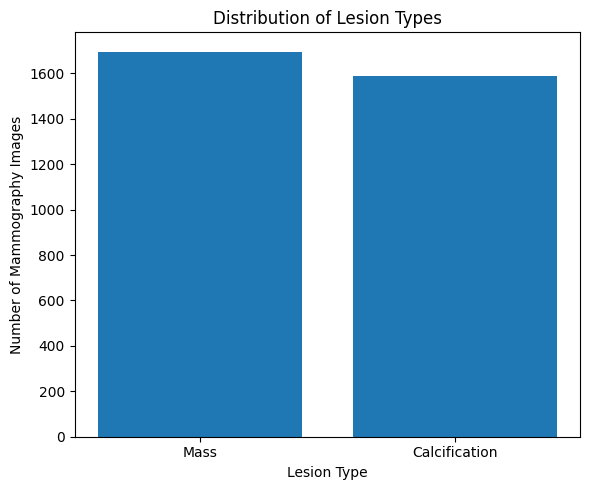

In [ ]:
# Analyse lesion type distribution
lesion_counts = final_data["lesion_type"].value_counts()

print("Lesion Type Counts:")
print(lesion_counts)

print("\nLesion Type Percentages:")
print(
    (final_data["lesion_type"].value_counts(normalize=True) * 100).round(2)
)

# Visualise lesion type distribution
plt.figure(figsize=(6, 5))

plt.bar(
    lesion_counts.index.str.capitalize(),
    lesion_counts.values
)

plt.title("Distribution of Lesion Types")
plt.xlabel("Lesion Type")
plt.ylabel("Number of Mammography Images")

plt.tight_layout()
plt.show()

### Mammography View Distribution

The distribution of Craniocaudal (CC) and Mediolateral Oblique (MLO) views was
examined to determine the representation of the two mammography views within the
prepared dataset.

Mammography View Counts:
match_id
MLO    1743
CC     1543
Name: count, dtype: int64

Mammography View Percentages:
match_id
MLO    53.04
CC     46.96
Name: proportion, dtype: float64

Missing View Values:
0


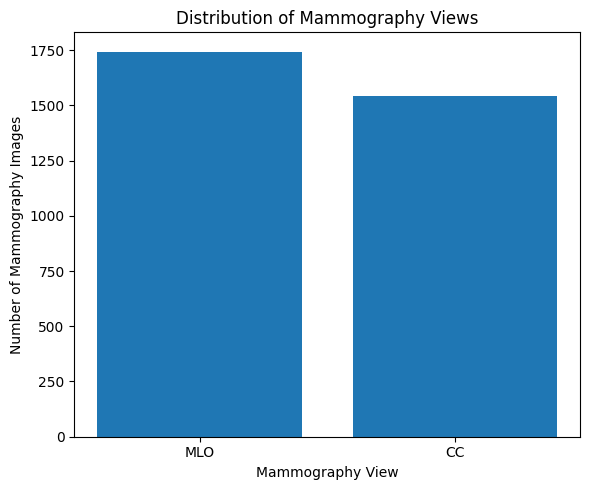

In [ ]:
# Extract mammography view without modifying final_df
mammography_view = final_data["match_id"].str.extract(
    r"_(CC|MLO)$",
    expand=False
)

view_counts = mammography_view.value_counts()

print("Mammography View Counts:")
print(view_counts)

print("\nMammography View Percentages:")
print(
    (mammography_view.value_counts(normalize=True) * 100).round(2)
)

print("\nMissing View Values:")
print(mammography_view.isna().sum())

plt.figure(figsize=(6, 5))

plt.bar(
    view_counts.index,
    view_counts.values
)

plt.title("Distribution of Mammography Views")
plt.xlabel("Mammography View")
plt.ylabel("Number of Mammography Images")

plt.tight_layout()
plt.show()

Number of Unique Patients:
1460

Patient-Level Class Counts:
Benign       752
Malignant    708
dtype: int64

Patient-Level Class Percentages:
Benign       51.51
Malignant    48.49
dtype: float64


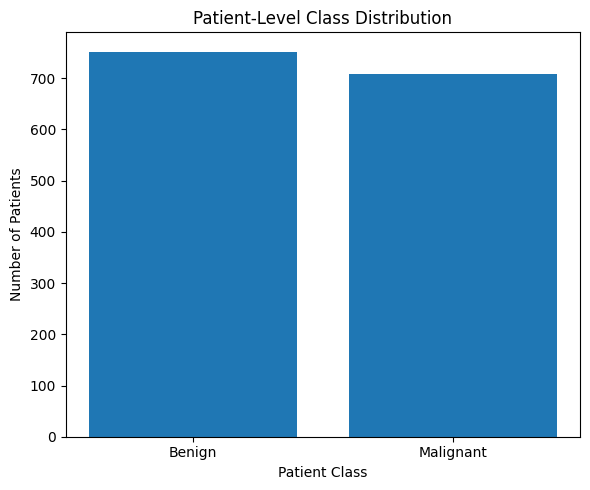

In [ ]:
# Create patient-level labels
# A patient is labelled malignant (1) if any associated image is malignant
patient_labels_eda = (
    final_data.groupby("patient_id")["label"]
    .max()
)

# Count patients in each class
patient_class_counts = patient_labels_eda.value_counts().sort_index()

print("Number of Unique Patients:")
print(len(patient_labels_eda))

print("\nPatient-Level Class Counts:")
print(
    pd.Series({
        "Benign": patient_class_counts.get(0, 0),
        "Malignant": patient_class_counts.get(1, 0)
    })
)

print("\nPatient-Level Class Percentages:")
print(
    pd.Series({
        "Benign": patient_class_counts.get(0, 0),
        "Malignant": patient_class_counts.get(1, 0)
    }).div(len(patient_labels_eda)).mul(100).round(2)
)

# Visualise patient-level class distribution
patient_plot_counts = pd.Series({
    "Benign": patient_class_counts.get(0, 0),
    "Malignant": patient_class_counts.get(1, 0)
})

plt.figure(figsize=(6, 5))

plt.bar(
    patient_plot_counts.index,
    patient_plot_counts.values
)

plt.title("Patient-Level Class Distribution")
plt.xlabel("Patient Class")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

### Representative Mammography Images

Representative benign and malignant full mammograms were visualised to inspect
the image characteristics of the two classification classes before preprocessing and
model development.

In [ ]:
# Select one representative image from each category

benign_mass = final_data[
    (final_data["label"] == 0) &
    (final_data["lesion_type"].str.lower() == "mass")
].sample(
    1,
    random_state=42
)

benign_calcification = final_data[
    (final_data["label"] == 0) &
    (final_data["lesion_type"].str.lower() == "calcification")
].sample(
    1,
    random_state=42
)

malignant_mass = final_data[
    (final_data["label"] == 1) &
    (final_data["lesion_type"].str.lower() == "mass")
].sample(
    1,
    random_state=42
)

malignant_calcification = final_data[
    (final_data["label"] == 1) &
    (final_data["lesion_type"].str.lower() == "calcification")
].sample(
    1,
    random_state=42
)

# Combine the four selected examples
sample_images = pd.concat([
    benign_mass,
    benign_calcification,
    malignant_mass,
    malignant_calcification
])

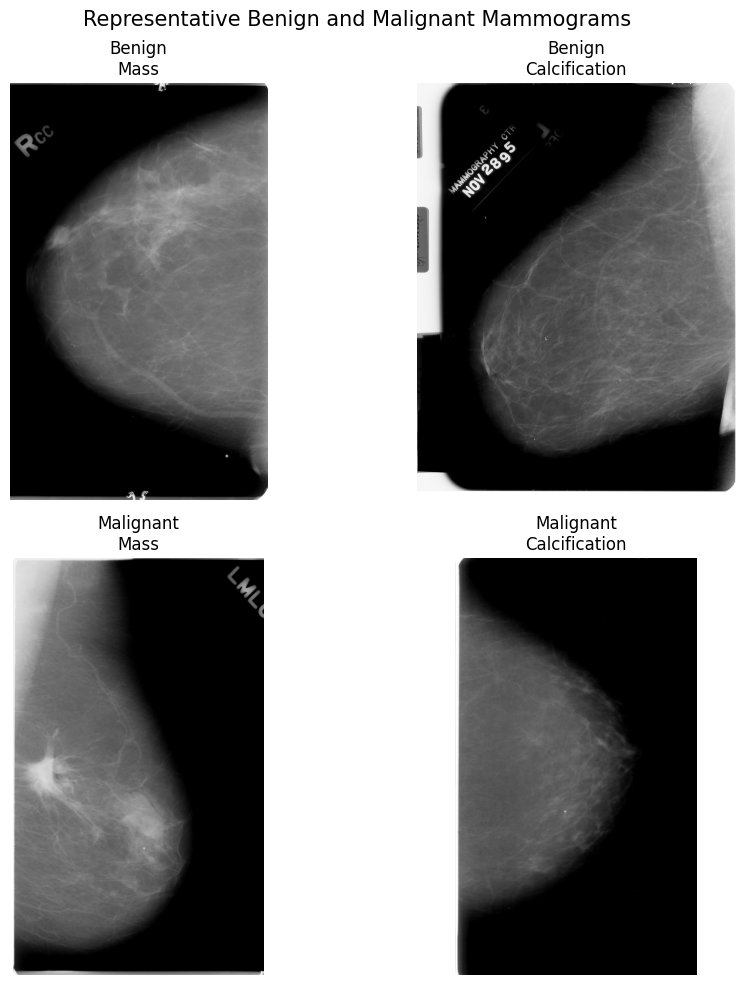

In [ ]:
plt.figure(figsize=(10, 10))

for i, (_, row) in enumerate(sample_images.iterrows()):

    img = tf.keras.utils.load_img(
        row["image_path"]
    )

    plt.subplot(2, 2, i + 1)

    plt.imshow(
        img,
        cmap="gray"
    )

    plt.axis("off")

    class_name = (
        "Benign"
        if row["label"] == 0
        else "Malignant"
    )

    lesion_name = row["lesion_type"].capitalize()

    plt.title(
        f"{class_name}\n{lesion_name}",
        fontsize=12
    )

plt.suptitle(
    "Representative Benign and Malignant Mammograms",
    fontsize=15
)

plt.tight_layout()
plt.show()

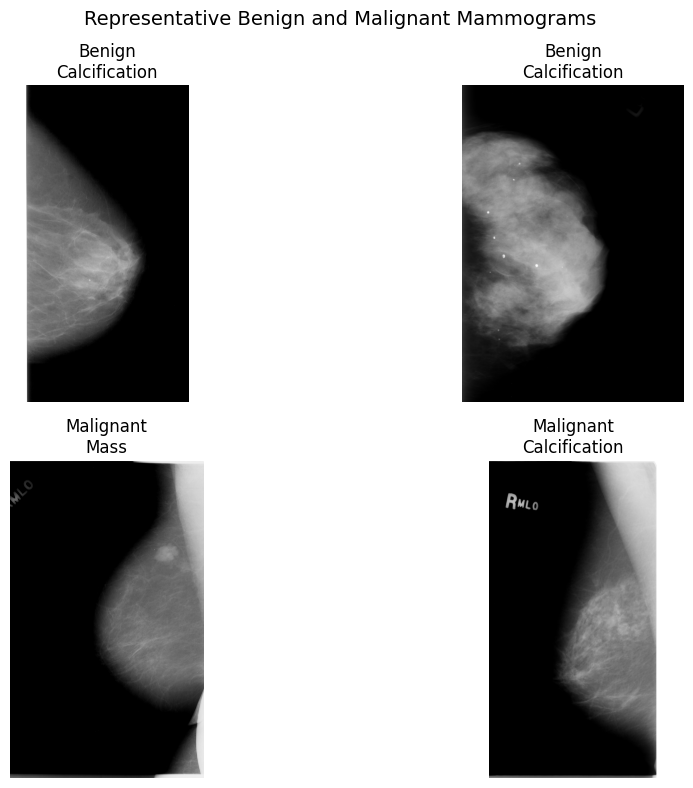

In [ ]:
# Select two benign and two malignant examples
benign_samples = final_data[final_data["label"] == 0].sample(
    2,
    random_state=42
)

malignant_samples = final_data[final_data["label"] == 1].sample(
    2,
    random_state=42
)

sample_images = pd.concat([
    benign_samples,
    malignant_samples
])

plt.figure(figsize=(12, 8))

for i, (_, row) in enumerate(sample_images.iterrows()):

    img = tf.keras.utils.load_img(
        row["image_path"]
    )

    plt.subplot(2, 2, i + 1)
    plt.imshow(img, cmap="gray")
    plt.axis("off")

    class_name = "Benign" if row["label"] == 0 else "Malignant"

    plt.title(
        f"{class_name}\n"
        f"{row['lesion_type'].capitalize()}"
    )

plt.suptitle(
    "Representative Benign and Malignant Mammograms",
    fontsize=14
)

plt.tight_layout()
plt.show()

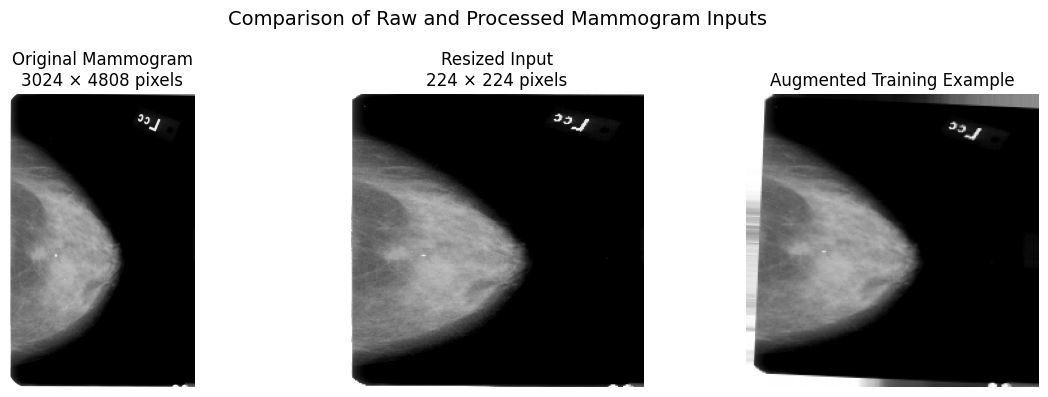

In [ ]:
# Select one representative mammogram
sample_path = final_data["image_path"].iloc[0]

# Load the original image
original_img = Image.open(sample_path).convert("L")

# Create the resized three-channel image used by the models
resized_img = tf.keras.utils.load_img(
    sample_path,
    target_size=(224, 224),
    color_mode="rgb"
)

resized_array = tf.keras.utils.img_to_array(resized_img)

# Use the same augmentation settings as model training
eda_augmentation = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

# Generate one reproducible augmented example
augmented_array = eda_augmentation.random_transform(
    resized_array,
    seed=42
)

augmented_array = np.clip(
    augmented_array,
    0,
    255
).astype("uint8")

# Display raw and processed versions
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_img, cmap="gray")
plt.title(
    f"Original Mammogram\n"
    f"{original_img.size[0]} × {original_img.size[1]} pixels"
)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(resized_img, cmap="gray")
plt.title("Resized Input\n224 × 224 pixels")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(augmented_array)
plt.title("Augmented Training Example")
plt.axis("off")

plt.suptitle(
    "Comparison of Raw and Processed Mammogram Inputs",
    fontsize=14
)

plt.tight_layout()
plt.show()

### EDA Summary

Exploratory Data Analysis was conducted on the prepared CBIS-DDSM dataset before
model development. After matching the case metadata with the available full mammogram
images, 3,286 mammograms from 1,460 unique patients were available for analysis.

The image-level class distribution contained 1,931 benign and 1,355 malignant
mammograms, indicating moderate class imbalance. At patient level, however, the
distribution was more balanced, with 752 benign and 708 malignant patients.

Analysis of lesion types showed that the dataset contained 1,696 mass images (51.61%)
and 1,590 calcification images (48.39%). The mammography views were also relatively
balanced, with 1,743 MLO images (53.04%) and 1,543 CC images (46.96%).

These findings influenced the subsequent implementation. Patient-level splitting was
used to reduce the risk of data leakage between the training, validation, and testing
sets, while stratification and class weighting were used to account for the observed
class distribution. Representative mammograms were also inspected to verify the
images used for model development.

## 7. Create Image Generators

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Training data uses augmentation to reduce overfitting
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

# Validation and test data should not be augmented
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=True,
    seed=SEED
)

val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='image_path',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=False
)

Found 2289 validated image filenames belonging to 2 classes.
Found 529 validated image filenames belonging to 2 classes.
Found 468 validated image filenames belonging to 2 classes.


## 8. Build and Compile Baseline CNN

In [ ]:
baseline_cnn = Sequential([
    Input(shape=(224, 224, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

baseline_cnn.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

baseline_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,985 (42.61 MB)

 Trainable params: 11,169,537 (42.61 MB)

 Non-trainable params: 448 (1.75 KB)

## 9. Train Baseline CNN

In [ ]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        '/content/drive/MyDrive/CM3070/best_baseline_cnn.keras',
        monitor='val_loss',
        save_best_only=True
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

EPOCHS = 30

history_cnn = baseline_cnn.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 1732s 24s/step - accuracy: 0.5304 - auc: 0.5408 - loss: 1.2229 - precision: 0.4444 - recall: 0.5599 - val_accuracy: 0.5974 - val_auc: 0.4642 - val_loss: 1.4443 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 276s 4s/step - accuracy: 0.5636 - auc: 0.5743 - loss: 0.7210 - precision: 0.4747 - recall: 0.5578 - val_accuracy: 0.5974 - val_auc: 0.5031 - val_loss: 2.6211 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 3/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 226s 3s/step - accuracy: 0.5832 - auc: 0.6025 - loss: 0.6982 - precision: 0.4949 - recall: 0.5695 - val_accuracy: 0.5974 - val_auc: 0.5238 - val_loss: 2.6423 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 4/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 233s 3s/step - accuracy: 0.5858 - auc: 0.6183 - loss: 0.6894 - precision: 0.4977 - recall: 0.5620 - val_accuracy: 0.5974 - val_au

In [ ]:
# Save the final model to Google Drive
baseline_cnn.save('/content/drive/MyDrive/CM3070/final_baseline_cnn.keras')

## 10. Plot Training Accuracy and Loss

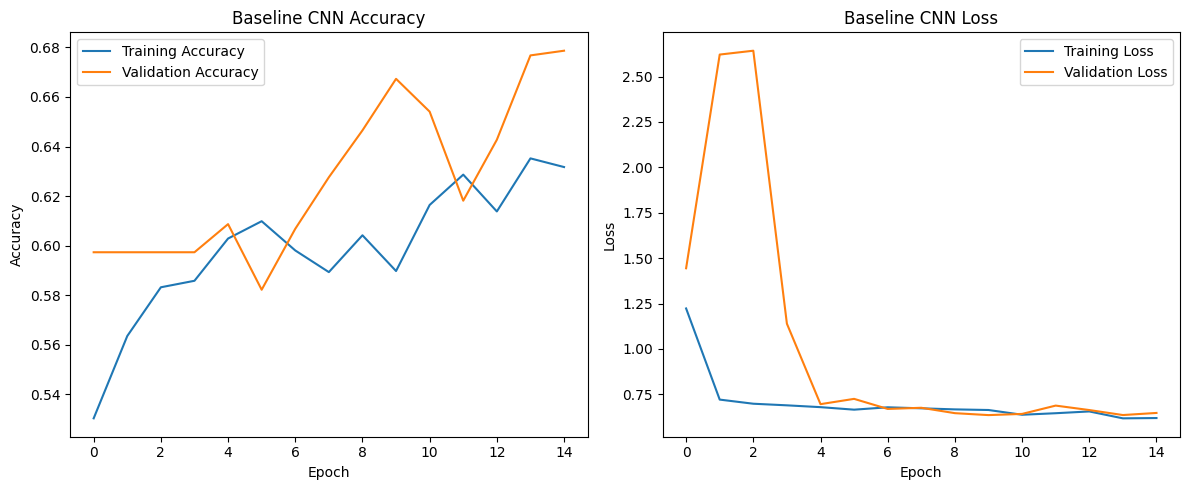

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Validation Accuracy')
plt.title('Baseline CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['loss'], label='Training Loss')
plt.plot(history_cnn.history['val_loss'], label='Validation Loss')
plt.title('Baseline CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 11. Evaluate Baseline CNN on Test Set

In [ ]:
test_results = baseline_cnn.evaluate(
    test_generator,
    return_dict=True
)

print(f"Test Loss: {test_results['loss']:.4f}")
print(f"Test Accuracy: {test_results['accuracy']:.4f}")
print(f"Test Precision: {test_results['precision']:.4f}")
print(f"Test Recall: {test_results['recall']:.4f}")
print(f"Test AUC: {test_results['auc']:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 263s 19s/step - accuracy: 0.6197 - auc: 0.6684 - loss: 0.6492 - precision: 0.5425 - recall: 0.6734
Test Loss: 0.6492
Test Accuracy: 0.6197
Test Precision: 0.5425
Test Recall: 0.6734
Test AUC: 0.6684


In [ ]:
# Generate predictions
y_pred_prob = baseline_cnn.predict(test_generator)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = test_generator.classes

15/15 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step


In [ ]:
# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=['Benign', 'Malignant']
))

              precision    recall  f1-score   support

      Benign       0.71      0.58      0.64       269
   Malignant       0.54      0.67      0.60       199

    accuracy                           0.62       468
   macro avg       0.62      0.63      0.62       468
weighted avg       0.64      0.62      0.62       468



True Negatives : 156
False Positives: 113
False Negatives: 65
True Positives : 134
[[156 113]
 [ 65 134]]


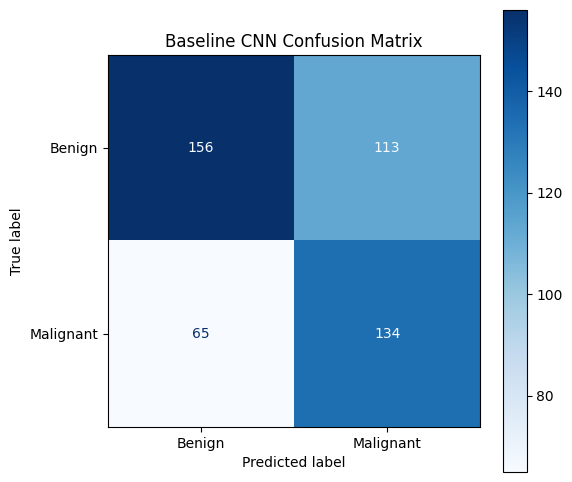

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

tn, fp, fn, tp = cm.ravel()

print('True Negatives :', tn)
print('False Positives:', fp)
print('False Negatives:', fn)
print('True Positives :', tp)
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benign', 'Malignant']
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Baseline CNN Confusion Matrix')
plt.show()

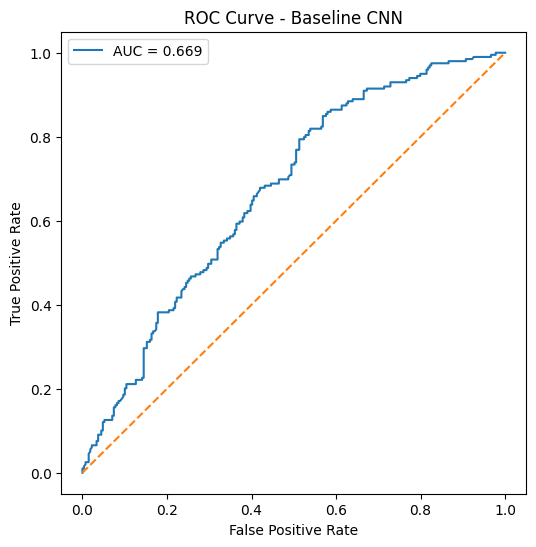

ROC-AUC Score: 0.668818068035344


In [ ]:
# ROC curve and AUC score
auc = roc_auc_score(y_true, y_pred_prob)
fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Baseline CNN')
plt.legend()
plt.show()

print('ROC-AUC Score:', auc)

## Network Scaling Experiment

To investigate the effect of network capacity on classification
performance, three CNN architectures of increasing complexity were
evaluated while maintaining the same dataset, preprocessing pipeline,
training configuration and evaluation metrics.

The experiment compares:
- Small CNN: two convolutional blocks
- Baseline CNN: three convolutional blocks
- Scaled CNN: four convolutional blocks

## Build and Compile Small CNN

In [ ]:
from tensorflow.keras import layers, models
tf.random.set_seed(42)

cnn_small = Sequential([

    Input(shape=(224, 224, 3)),

    # Convolutional Block 1
    Conv2D(32, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Convolutional Block 2
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Classification layers
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    # Output
    Dense(1, activation='sigmoid')
])

cnn_small.summary()

cnn_small.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,907,905 (91.20 MB)

 Trainable params: 23,907,713 (91.20 MB)

 Non-trainable params: 192 (768.00 B)

## Train Small CNN

In [ ]:
callbacks_small = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        '/content/drive/MyDrive/CM3070/best_cnn_small.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

EPOCHS = 30

history_small = cnn_small.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks_small,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 249s 3s/step - accuracy: 0.5260 - auc: 0.5304 - loss: 2.9173 - precision: 0.4364 - recall: 0.5164 - val_accuracy: 0.5879 - val_auc: 0.6211 - val_loss: 0.6663 - val_precision: 0.3077 - val_recall: 0.0188 - learning_rate: 1.0000e-04
Epoch 2/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 235s 3s/step - accuracy: 0.5561 - auc: 0.5570 - loss: 0.7566 - precision: 0.4580 - recall: 0.4221 - val_accuracy: 0.6011 - val_auc: 0.6363 - val_loss: 0.7913 - val_precision: 0.7500 - val_recall: 0.0141 - learning_rate: 1.0000e-04
Epoch 3/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 229s 3s/step - accuracy: 0.5723 - auc: 0.5694 - loss: 0.7439 - precision: 0.4816 - recall: 0.5005 - val_accuracy: 0.5992 - val_auc: 0.6441 - val_loss: 0.7854 - val_precision: 0.5714 - val_recall: 0.0188 - learning_rate: 1.0000e-04
Epoch 4/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 233s 3s/step - accuracy: 0.5592 - auc: 0.5947 - loss: 0.7072 - precision: 0.4697 - recall: 0.5429 - val_accuracy: 0.5936 - val_auc: 0.6387 - val_loss: 0.75

In [ ]:
test_loss, test_acc, test_precision, test_recall, test_auc = cnn_small.evaluate(
    test_generator,
    verbose=1
)

print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test AUC:       {test_auc:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.6474 - auc: 0.7179 - loss: 0.6347 - precision: 0.5702 - recall: 0.6935
Test Loss:      0.6347
Test Accuracy:  0.6474
Test Precision: 0.5702
Test Recall:    0.6935
Test AUC:       0.7179


In [ ]:
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

test_generator.reset()

y_prob_small = cnn_small.predict(
    test_generator,
    verbose=1
).ravel()

y_pred_small = (y_prob_small >= 0.5).astype(int)

y_true_small = test_generator.classes

small_f1 = f1_score(y_true_small, y_pred_small)

print(f"Test F1-score: {small_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true_small,
        y_pred_small,
        target_names=['Benign', 'Malignant']
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true_small, y_pred_small))

15/15 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step
Test F1-score: 0.6259

Classification Report:
              precision    recall  f1-score   support

      Benign       0.73      0.61      0.67       269
   Malignant       0.57      0.69      0.63       199

    accuracy                           0.65       468
   macro avg       0.65      0.65      0.65       468
weighted avg       0.66      0.65      0.65       468


Confusion Matrix:
[[165 104]
 [ 61 138]]


## Build & Compile Scaled CNN

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    BatchNormalization,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

tf.random.set_seed(42)

cnn_scaled = Sequential([

    Input(shape=(224, 224, 3)),

    # Convolutional Block 1
    Conv2D(32, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Convolutional Block 2
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Convolutional Block 3
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Convolutional Block 4
    Conv2D(256, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Classification layers
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    # Binary classification output
    Dense(1, activation='sigmoid')
])

cnn_scaled.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     4,718,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,109,185 (19.49 MB)

 Trainable params: 5,108,225 (19.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
cnn_scaled.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

## Train Scaled CNN

In [ ]:
callbacks_scaled = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        '/content/drive/MyDrive/CM3070/best_cnn_scaled.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

EPOCHS = 30

history_scaled = cnn_scaled.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks_scaled,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 244s 3s/step - accuracy: 0.5535 - auc: 0.5620 - loss: 0.9983 - precision: 0.4633 - recall: 0.5292 - val_accuracy: 0.5974 - val_auc: 0.4634 - val_loss: 0.9854 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 230s 3s/step - accuracy: 0.5583 - auc: 0.5939 - loss: 0.7062 - precision: 0.4708 - recall: 0.5822 - val_accuracy: 0.5974 - val_auc: 0.4904 - val_loss: 2.0721 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 3/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 239s 3s/step - accuracy: 0.5898 - auc: 0.6225 - loss: 0.6894 - precision: 0.5018 - recall: 0.5960 - val_accuracy: 0.5974 - val_auc: 0.5246 - val_loss: 1.8462 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 4/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 227s 3s/step - accuracy: 0.5924 - auc: 0.6364 - loss: 0.6708 - precision: 0.5041 - recall: 0.6575 - val_accuracy: 0.5974 - val_auc:

In [ ]:
test_loss, test_acc, test_precision, test_recall, test_auc = cnn_scaled.evaluate(
    test_generator,
    verbose=1
)

print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test AUC:       {test_auc:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.6368 - auc: 0.7025 - loss: 0.6259 - precision: 0.5612 - recall: 0.6683
Test Loss:      0.6259
Test Accuracy:  0.6368
Test Precision: 0.5612
Test Recall:    0.6683
Test AUC:       0.7025


In [ ]:
test_generator.reset()

y_prob_scaled = cnn_scaled.predict(
    test_generator,
    verbose=1
).ravel()

y_pred_scaled = (y_prob_scaled >= 0.5).astype(int)

y_true_scaled = test_generator.classes

scaled_f1 = f1_score(
    y_true_scaled,
    y_pred_scaled
)

print(f"Test F1-score: {scaled_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true_scaled,
        y_pred_scaled,
        target_names=['Benign', 'Malignant']
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_true_scaled,
        y_pred_scaled
    )
)

15/15 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step
Test F1-score: 0.6101

Classification Report:
              precision    recall  f1-score   support

      Benign       0.71      0.61      0.66       269
   Malignant       0.56      0.67      0.61       199

    accuracy                           0.64       468
   macro avg       0.64      0.64      0.64       468
weighted avg       0.65      0.64      0.64       468


Confusion Matrix:
[[165 104]
 [ 66 133]]


The network-scaling experiment compared CNN architectures containing two, three and four convolutional blocks while maintaining consistent preprocessing, optimisation, class weighting and training settings. Contrary to the expectation that increased depth would improve performance, the two-block CNN achieved the strongest overall test performance, with an accuracy of 64.74%, recall of 69.35% and AUC of 0.7179. The three-block baseline achieved the lowest AUC of 0.6688, while the four-block scaled CNN improved to 0.7025 but remained below the smaller CNN. These findings indicate that increasing convolutional depth alone did not consistently improve generalisation on the CBIS-DDSM dataset.

## 12. ResNet50 Transfer Learning

In [ ]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

In [ ]:
# ResNet50 data generators
resnet_train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

resnet_val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

resnet_train_generator = resnet_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=SEED
)

resnet_val_generator = resnet_val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

resnet_test_generator = resnet_val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 2289 validated image filenames belonging to 2 classes.
Found 529 validated image filenames belonging to 2 classes.
Found 468 validated image filenames belonging to 2 classes.


In [ ]:
resnet_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers during the first training stage
resnet_base.trainable = False

print("ResNet50 base loaded.")

ResNet50 base loaded.


In [ ]:
resnet_model = tf.keras.Sequential([
    resnet_base,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(
        1,
        activation='sigmoid'
    )
])

resnet_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
resnet_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [ ]:
resnet_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        '/content/drive/MyDrive/CM3070/best_resnet50_frozen.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

history_resnet = resnet_model.fit(
    resnet_train_generator,
    validation_data=resnet_val_generator,
    epochs=20,
    callbacks=resnet_callbacks,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 243s 3s/step - accuracy: 0.4814 - auc: 0.4768 - loss: 0.9031 - precision: 0.3973 - recall: 0.5005 - val_accuracy: 0.5558 - val_auc: 0.5675 - val_loss: 0.6885 - val_precision: 0.4509 - val_recall: 0.4742 - learning_rate: 1.0000e-04
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 227s 3s/step - accuracy: 0.5063 - auc: 0.5163 - loss: 0.8463 - precision: 0.4203 - recall: 0.5228 - val_accuracy: 0.5822 - val_auc: 0.6022 - val_loss: 0.6779 - val_precision: 0.4833 - val_recall: 0.5446 - learning_rate: 1.0000e-04
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 228s 3s/step - accuracy: 0.5247 - auc: 0.5312 - loss: 0.8213 - precision: 0.4374 - recall: 0.5376 - val_accuracy: 0.6087 - val_auc: 0.6307 - val_loss: 0.6557 - val_precision: 0.5167 - val_recall: 0.4366 - learning_rate: 1.0000e-04
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 229s 3s/step - accuracy: 0.5129 - auc: 0.5220 - loss: 0.8280 - precision: 0.4250 - recall: 0.5164 - val_accuracy: 0.6219 - val_auc: 0.6529 - val_loss: 0.65

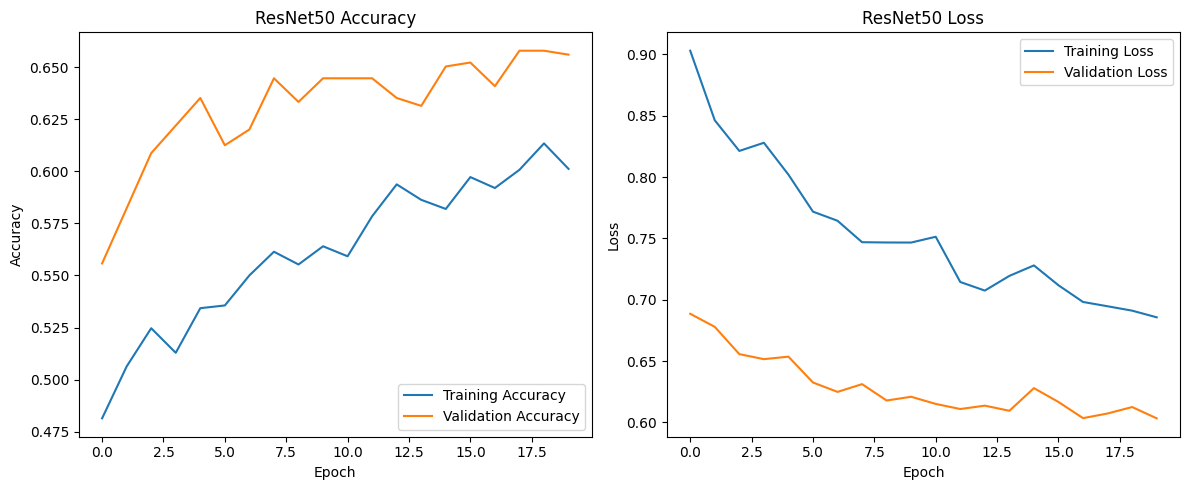

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(history_resnet.history['accuracy'], label='Training Accuracy')
plt.plot(history_resnet.history['val_accuracy'], label='Validation Accuracy')
plt.title('ResNet50 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(history_resnet.history['loss'], label='Training Loss')
plt.plot(history_resnet.history['val_loss'], label='Validation Loss')
plt.title('ResNet50 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
resnet_results = resnet_model.evaluate(
    resnet_test_generator,
    return_dict=True
)

print(f"Test Loss: {resnet_results['loss']:.4f}")
print(f"Test Accuracy: {resnet_results['accuracy']:.4f}")
print(f"Test Precision: {resnet_results['precision']:.4f}")
print(f"Test Recall: {resnet_results['recall']:.4f}")
print(f"Test AUC: {resnet_results['auc']:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.6453 - auc: 0.7334 - loss: 0.5992 - precision: 0.5892 - recall: 0.5477
Test Loss: 0.5992
Test Accuracy: 0.6453
Test Precision: 0.5892
Test Recall: 0.5477
Test AUC: 0.7334


In [ ]:
resnet_test_generator.reset()

resnet_y_prob = resnet_model.predict(
    resnet_test_generator
).ravel()

resnet_y_pred = (
    resnet_y_prob >= 0.5
).astype(int)

resnet_y_true = resnet_test_generator.classes

15/15 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step


In [ ]:
print(
    classification_report(
        resnet_y_true,
        resnet_y_pred,
        target_names=['Benign', 'Malignant'],
        digits=4
    )
)

              precision    recall  f1-score   support

      Benign     0.6820    0.7175    0.6993       269
   Malignant     0.5892    0.5477    0.5677       199

    accuracy                         0.6453       468
   macro avg     0.6356    0.6326    0.6335       468
weighted avg     0.6425    0.6453    0.6433       468



In [ ]:
resnet_cm = confusion_matrix(
    resnet_y_true,
    resnet_y_pred
)

tn, fp, fn, tp = resnet_cm.ravel()

print('True Negatives :', tn)
print('False Positives:', fp)
print('False Negatives:', fn)
print('True Positives :', tp)
print(resnet_cm)

True Negatives : 193
False Positives: 76
False Negatives: 90
True Positives : 109
[[193  76]
 [ 90 109]]


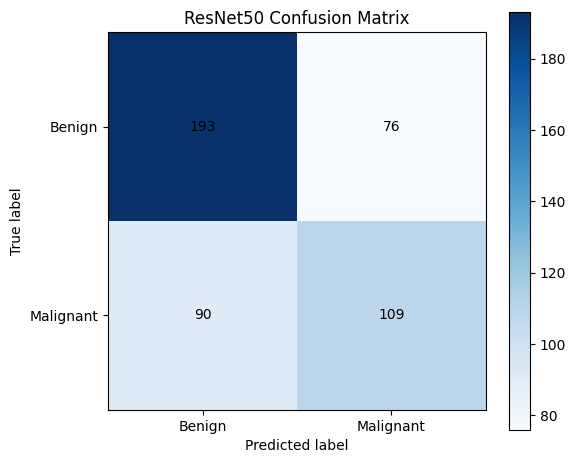

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(resnet_cm, cmap='Blues')
plt.title('ResNet50 Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.xticks([0, 1], ['Benign', 'Malignant'])
plt.yticks([0, 1], ['Benign', 'Malignant'])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            resnet_cm[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.tight_layout()
plt.show()

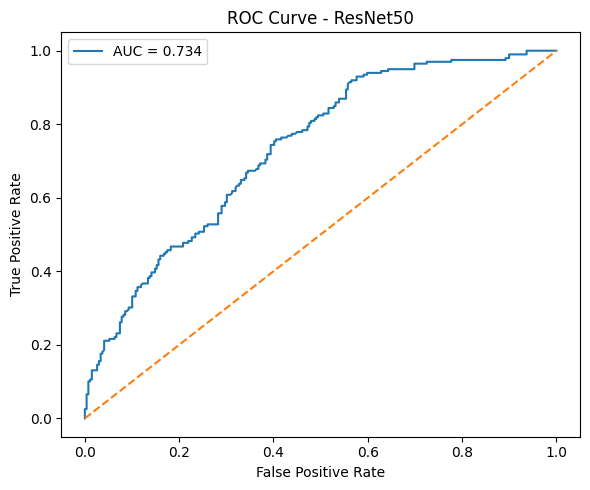

ROC-AUC Score: 0.7336590013263342


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

resnet_auc = roc_auc_score(
    resnet_y_true,
    resnet_y_prob
)

fpr, tpr, thresholds = roc_curve(
    resnet_y_true,
    resnet_y_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f'AUC = {resnet_auc:.3f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - ResNet50')
plt.legend()

plt.tight_layout()
plt.show()

print('ROC-AUC Score:', resnet_auc)

## 12.1 ResNet50 Fine-Tuning

Following the initial transfer learning stage, the upper convolutional
layers of ResNet50 were fine-tuned to allow higher-level pretrained
features to adapt to the mammography classification task.

The earlier ResNet50 layers were kept frozen, while the final conv5
stage was made trainable. Batch Normalisation layers remained frozen
to preserve their pretrained statistics. A lower learning rate was
used during fine-tuning to avoid large changes to the pretrained
weights.

In [ ]:
resnet_base.trainable = True

for layer in resnet_base.layers:

    # Fine-tune only the final ResNet50 stage
    if layer.name.startswith('conv5_'):
        layer.trainable = True
    else:
        layer.trainable = False

    # Keep Batch Normalisation layers frozen
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [ ]:
print("Trainable ResNet50 layers:")
print("-" * 40)

trainable_count = 0

for layer in resnet_base.layers:
    if layer.trainable:
        print(layer.name)
        trainable_count += 1

print("-" * 40)
print("Number of trainable ResNet50 layers:", trainable_count)

Trainable ResNet50 layers:
----------------------------------------
conv5_block1_1_conv
conv5_block1_1_relu
conv5_block1_2_conv
conv5_block1_2_relu
conv5_block1_0_conv
conv5_block1_3_conv
conv5_block1_add
conv5_block1_out
conv5_block2_1_conv
conv5_block2_1_relu
conv5_block2_2_conv
conv5_block2_2_relu
conv5_block2_3_conv
conv5_block2_add
conv5_block2_out
conv5_block3_1_conv
conv5_block3_1_relu
conv5_block3_2_conv
conv5_block3_2_relu
conv5_block3_3_conv
conv5_block3_add
conv5_block3_out
----------------------------------------
Number of trainable ResNet50 layers: 22


In [ ]:
trainable_params = np.sum([
    np.prod(weight.shape)
    for weight in resnet_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(weight.shape)
    for weight in resnet_model.non_trainable_weights
])

print(f"Trainable parameters:     {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

Trainable parameters:     14,955,521
Non-trainable parameters: 8,634,240


In [ ]:
resnet_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [ ]:
resnet_ft_callbacks = [

    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        '/content/drive/MyDrive/CM3070/best_resnet50_finetuned.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

FINE_TUNE_EPOCHS = 20

history_resnet_ft = resnet_model.fit(
    resnet_train_generator,
    validation_data=resnet_val_generator,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=resnet_ft_callbacks,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 252s 3s/step - accuracy: 0.6134 - auc: 0.6568 - loss: 0.6630 - precision: 0.5269 - recall: 0.6023 - val_accuracy: 0.6616 - val_auc: 0.7387 - val_loss: 0.6116 - val_precision: 0.5859 - val_recall: 0.5446 - learning_rate: 1.0000e-05
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 229s 3s/step - accuracy: 0.6531 - auc: 0.7015 - loss: 0.6312 - precision: 0.5689 - recall: 0.6522 - val_accuracy: 0.6578 - val_auc: 0.7580 - val_loss: 0.5994 - val_precision: 0.5593 - val_recall: 0.7089 - learning_rate: 1.0000e-05
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 231s 3s/step - accuracy: 0.6566 - auc: 0.7218 - loss: 0.6134 - precision: 0.5714 - recall: 0.6660 - val_accuracy: 0.6673 - val_auc: 0.7657 - val_loss: 0.6199 - val_precision: 0.5546 - val_recall: 0.8826 - learning_rate: 1.0000e-05
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 229s 3s/step - accuracy: 0.6732 - auc: 0.7512 - loss: 0.5861 - precision: 0.5846 - recall: 0.7147 - val_accuracy: 0.6654 - val_auc: 0.7736 - val_loss: 0.58

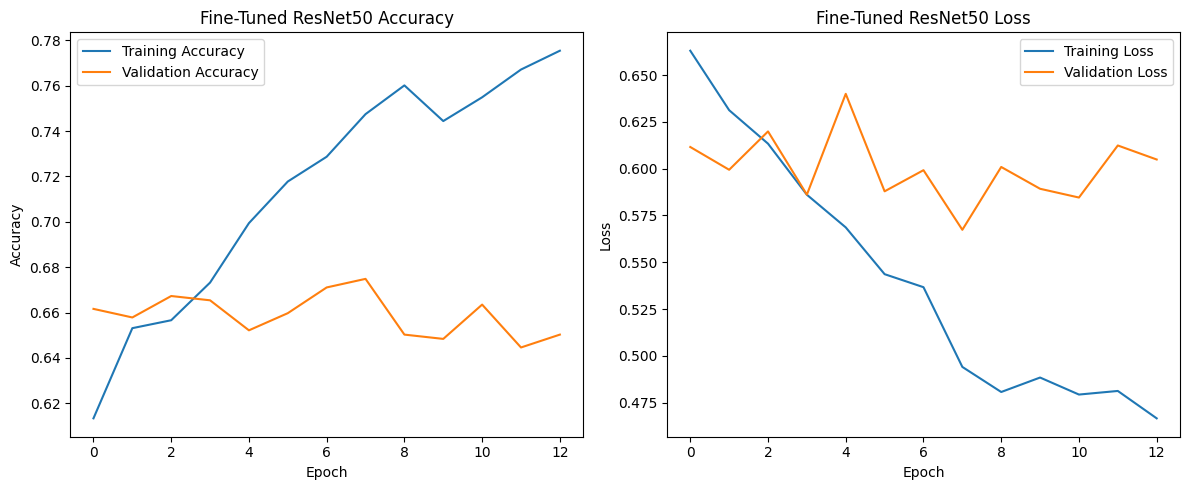

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_resnet_ft.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_resnet_ft.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Fine-Tuned ResNet50 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_resnet_ft.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_resnet_ft.history['val_loss'],
    label='Validation Loss'
)

plt.title('Fine-Tuned ResNet50 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
resnet_ft_results = resnet_model.evaluate(
    resnet_test_generator,
    return_dict=True
)

print("Fine-Tuned ResNet50 Test Results")
print("-" * 40)

print(f"Test Loss:      {resnet_ft_results['loss']:.4f}")
print(f"Test Accuracy:  {resnet_ft_results['accuracy']:.4f}")
print(f"Test Precision: {resnet_ft_results['precision']:.4f}")
print(f"Test Recall:    {resnet_ft_results['recall']:.4f}")
print(f"Test AUC:       {resnet_ft_results['auc']:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.7009 - auc: 0.7844 - loss: 0.5545 - precision: 0.6398 - recall: 0.6784
Fine-Tuned ResNet50 Test Results
----------------------------------------
Test Loss:      0.5545
Test Accuracy:  0.7009
Test Precision: 0.6398
Test Recall:    0.6784
Test AUC:       0.7844


In [ ]:
resnet_test_generator.reset()

resnet_ft_y_prob = resnet_model.predict(
    resnet_test_generator,
    verbose=1
).ravel()

resnet_ft_y_pred = (
    resnet_ft_y_prob >= 0.5
).astype(int)

resnet_ft_y_true = resnet_test_generator.classes

15/15 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve
)

resnet_ft_f1 = f1_score(
    resnet_ft_y_true,
    resnet_ft_y_pred
)

print(f"Fine-Tuned ResNet50 F1-score: {resnet_ft_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        resnet_ft_y_true,
        resnet_ft_y_pred,
        target_names=['Benign', 'Malignant'],
        digits=4
    )
)

Fine-Tuned ResNet50 F1-score: 0.6585

Classification Report:
              precision    recall  f1-score   support

      Benign     0.7510    0.7175    0.7338       269
   Malignant     0.6398    0.6784    0.6585       199

    accuracy                         0.7009       468
   macro avg     0.6954    0.6979    0.6962       468
weighted avg     0.7037    0.7009    0.7018       468



True Negatives : 193
False Positives: 76
False Negatives: 64
True Positives : 135

Confusion Matrix:
[[193  76]
 [ 64 135]]


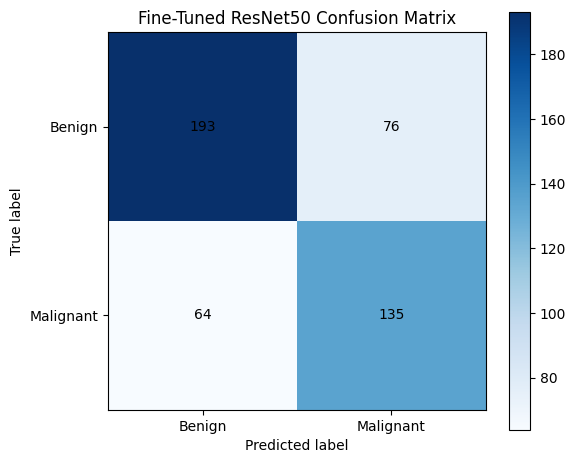

In [ ]:
resnet_ft_cm = confusion_matrix(
    resnet_ft_y_true,
    resnet_ft_y_pred
)

tn, fp, fn, tp = resnet_ft_cm.ravel()

print('True Negatives :', tn)
print('False Positives:', fp)
print('False Negatives:', fn)
print('True Positives :', tp)

print("\nConfusion Matrix:")
print(resnet_ft_cm)

plt.figure(figsize=(6, 5))

plt.imshow(resnet_ft_cm, cmap='Blues')

plt.title('Fine-Tuned ResNet50 Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.xticks([0, 1], ['Benign', 'Malignant'])
plt.yticks([0, 1], ['Benign', 'Malignant'])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            resnet_ft_cm[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.tight_layout()
plt.show()

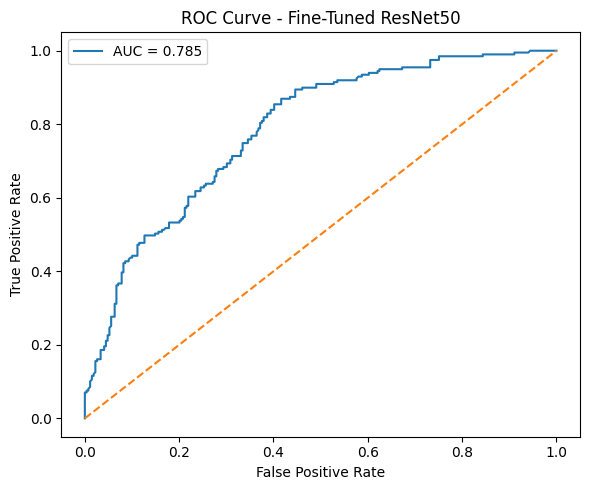

ROC-AUC Score: 0.784564084362332


In [ ]:
resnet_ft_auc = roc_auc_score(
    resnet_ft_y_true,
    resnet_ft_y_prob
)

resnet_ft_fpr, resnet_ft_tpr, resnet_ft_thresholds = roc_curve(
    resnet_ft_y_true,
    resnet_ft_y_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    resnet_ft_fpr,
    resnet_ft_tpr,
    label=f'AUC = {resnet_ft_auc:.3f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fine-Tuned ResNet50')
plt.legend()

plt.tight_layout()
plt.show()

print('ROC-AUC Score:', resnet_ft_auc)

Fine-tuning the final ResNet50 convolutional stage improved overall classification performance compared with the frozen transfer-learning model. Accuracy increased from 0.6453 to 0.7009, recall increased from 0.5477 to 0.6784, F1-score increased from 0.5677 to 0.6585, and ROC-AUC increased from 0.7337 to 0.7846. The number of false negatives decreased from 90 to 64, while false positives remained unchanged at 76. These results indicate that fine-tuning improved malignant-case sensitivity and overall discrimination without increasing the false-positive count at the default 0.50 threshold.

### Frozen vs Fine-Tuned ResNet50 Comparison

Fine-tuning the final ResNet50 convolutional stage improved overall
classification performance compared with the frozen transfer-learning
model. In particular, recall and ROC-AUC increased, indicating improved
sensitivity to malignant cases and stronger overall discrimination.

Fine-tuning reduced the number of false-negative predictions, although
this was accompanied by an increase in false-positive predictions.
This demonstrates a trade-off between malignant-case sensitivity and
false-positive classification.

## 13. EfficientNet Transfer Learning

In [ ]:
from tensorflow.keras.applications import EfficientNetB0

In [ ]:
efficient_train_datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

efficient_val_test_datagen = ImageDataGenerator()

efficient_train_generator = efficient_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=SEED
)

efficient_val_generator = efficient_val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

efficient_test_generator = efficient_val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 2289 validated image filenames belonging to 2 classes.
Found 529 validated image filenames belonging to 2 classes.
Found 468 validated image filenames belonging to 2 classes.


In [ ]:
efficient_base = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

efficient_base.trainable = False

In [ ]:
efficient_model = tf.keras.Sequential([
    efficient_base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

efficient_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
efficient_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [ ]:
efficient_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        '/content/drive/MyDrive/CM3070/best_efficientnetB0_frozen.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]
history_efficient = efficient_model.fit(
    efficient_train_generator,
    validation_data=efficient_val_generator,
    epochs=20,
    callbacks=efficient_callbacks,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 268s 4s/step - accuracy: 0.5234 - auc: 0.4860 - loss: 0.7463 - precision: 0.3969 - recall: 0.3022 - val_accuracy: 0.5539 - val_auc: 0.4581 - val_loss: 0.6924 - val_precision: 0.3425 - val_recall: 0.1174 - learning_rate: 1.0000e-04
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 229s 3s/step - accuracy: 0.4985 - auc: 0.4848 - loss: 0.7349 - precision: 0.4027 - recall: 0.4496 - val_accuracy: 0.5350 - val_auc: 0.4931 - val_loss: 0.6869 - val_precision: 0.3366 - val_recall: 0.1596 - learning_rate: 1.0000e-04
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 238s 3s/step - accuracy: 0.5291 - auc: 0.5259 - loss: 0.7129 - precision: 0.4364 - recall: 0.4910 - val_accuracy: 0.5482 - val_auc: 0.5320 - val_loss: 0.6809 - val_precision: 0.3898 - val_recall: 0.2160 - learning_rate: 1.0000e-04
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 227s 3s/step - accuracy: 0.5225 - auc: 0.5281 - loss: 0.7155 - precision: 0.4346 - recall: 0.5281 - val_accuracy: 0.5633 - val_auc: 0.5639 - val_loss: 0.67

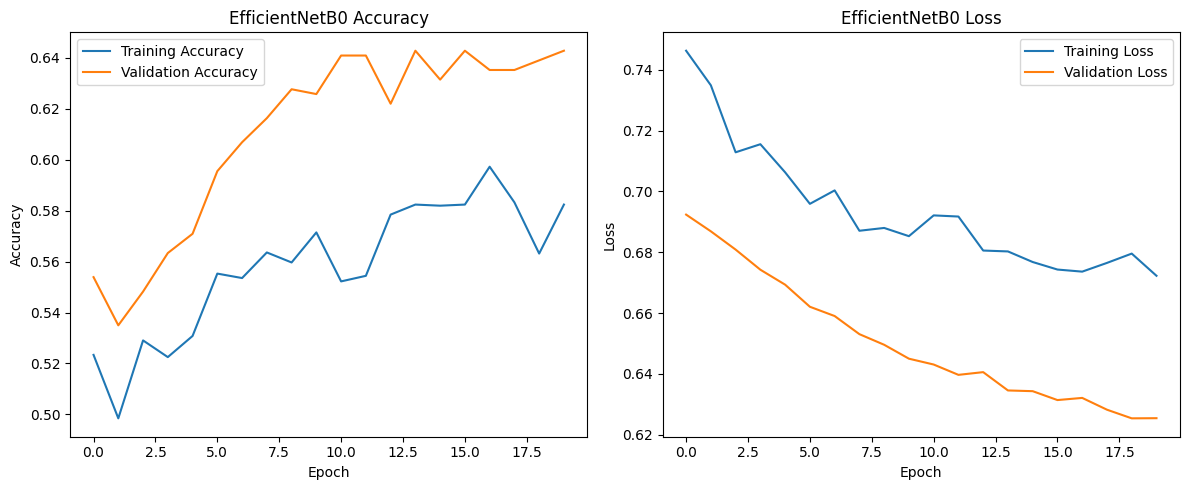

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(history_efficient.history['accuracy'], label='Training Accuracy')
plt.plot(history_efficient.history['val_accuracy'], label='Validation Accuracy')
plt.title('EfficientNetB0 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(history_efficient.history['loss'], label='Training Loss')
plt.plot(history_efficient.history['val_loss'], label='Validation Loss')
plt.title('EfficientNetB0 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
efficient_results = efficient_model.evaluate(
    efficient_test_generator,
    return_dict=True
)

print(f"Test Loss: {efficient_results['loss']:.4f}")
print(f"Test Accuracy: {efficient_results['accuracy']:.4f}")
print(f"Test Precision: {efficient_results['precision']:.4f}")
print(f"Test Recall: {efficient_results['recall']:.4f}")
print(f"Test AUC: {efficient_results['auc']:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 53s 4s/step - accuracy: 0.6560 - auc: 0.7127 - loss: 0.6302 - precision: 0.6397 - recall: 0.4372
Test Loss: 0.6302
Test Accuracy: 0.6560
Test Precision: 0.6397
Test Recall: 0.4372
Test AUC: 0.7127


In [ ]:
# Reset test generator before prediction
efficient_test_generator.reset()

# Predicted probabilities
efficient_y_prob = efficient_model.predict(
    efficient_test_generator
).ravel()

# Convert probabilities to binary predictions using threshold = 0.5
efficient_y_pred = (efficient_y_prob >= 0.5).astype(int)

# True labels
efficient_y_true = efficient_test_generator.classes

print("Number of test samples:", len(efficient_y_true))

15/15 ━━━━━━━━━━━━━━━━━━━━ 47s 3s/step
Number of test samples: 468


In [ ]:
print(
    classification_report(
        efficient_y_true,
        efficient_y_pred,
        target_names=['Benign', 'Malignant'],
        digits=4
    )
)

              precision    recall  f1-score   support

      Benign     0.6627    0.8178    0.7321       269
   Malignant     0.6397    0.4372    0.5194       199

    accuracy                         0.6560       468
   macro avg     0.6512    0.6275    0.6258       468
weighted avg     0.6529    0.6560    0.6417       468



In [ ]:
efficient_cm = confusion_matrix(
    efficient_y_true,
    efficient_y_pred
)

tn, fp, fn, tp = efficient_cm.ravel()

print('True Negatives :', tn)
print('False Positives:', fp)
print('False Negatives:', fn)
print('True Positives :', tp)

print('\nConfusion Matrix:')
print(efficient_cm)

True Negatives : 220
False Positives: 49
False Negatives: 112
True Positives : 87

Confusion Matrix:
[[220  49]
 [112  87]]


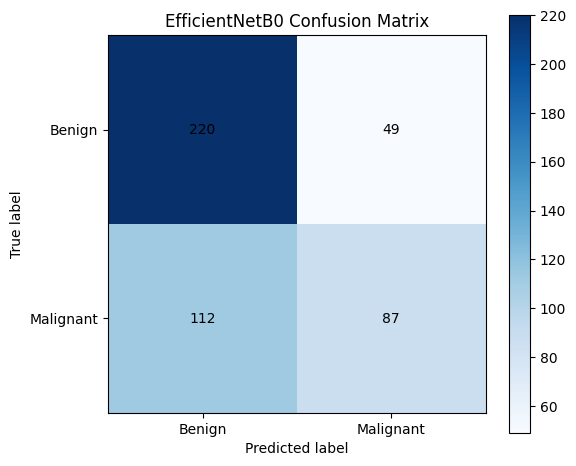

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(
    efficient_cm,
    cmap='Blues'
)

plt.title('EfficientNetB0 Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.xticks(
    [0, 1],
    ['Benign', 'Malignant']
)

plt.yticks(
    [0, 1],
    ['Benign', 'Malignant']
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            efficient_cm[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.tight_layout()
plt.show()

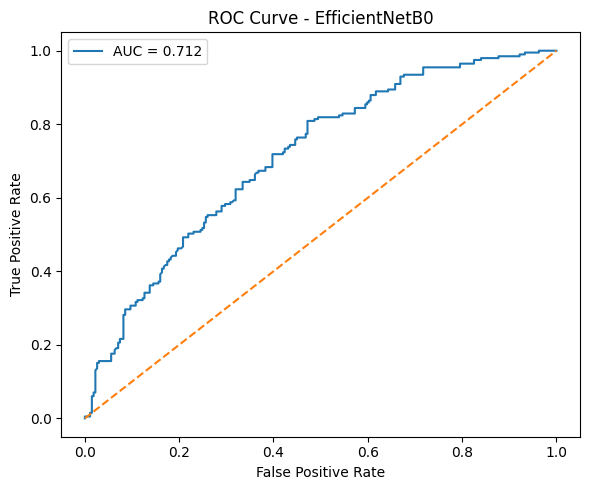

ROC-AUC Score: 0.7124563337131755


In [ ]:
efficient_auc = roc_auc_score(
    efficient_y_true,
    efficient_y_prob
)

efficient_fpr, efficient_tpr, efficient_thresholds = roc_curve(
    efficient_y_true,
    efficient_y_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    efficient_fpr,
    efficient_tpr,
    label=f'AUC = {efficient_auc:.3f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - EfficientNetB0')

plt.legend()
plt.tight_layout()
plt.show()

print('ROC-AUC Score:', efficient_auc)

## 13.1 EfficientNetB0 Fine-Tuning

Following the initial frozen transfer learning stage, the upper layers
of EfficientNetB0 were fine-tuned to allow pretrained high-level image
features to adapt more closely to the mammography classification task.

The earlier EfficientNetB0 layers were kept frozen, while a subset of
the final layers was made trainable. Batch Normalisation layers
remained frozen to preserve their pretrained statistics. A lower
learning rate was used during fine-tuning to reduce the risk of
disrupting the pretrained weights.

In [ ]:
# ============================================================
# EfficientNetB0 Fine-Tuning
# Unfreeze only the final 30 layers
# ============================================================

efficient_base.trainable = True

# Freeze all layers except the final 30
for layer in efficient_base.layers[:-30]:
    layer.trainable = False

for layer in efficient_base.layers[-30:]:
    layer.trainable = True

    # Keep Batch Normalisation layers frozen
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [ ]:
print("Trainable EfficientNetB0 layers:")
print("-" * 50)

trainable_count = 0

for layer in efficient_base.layers:
    if layer.trainable:
        print(layer.name)
        trainable_count += 1

print("-" * 50)
print("Number of trainable EfficientNetB0 layers:", trainable_count)

Trainable EfficientNetB0 layers:
--------------------------------------------------
block6d_expand_activation
block6d_dwconv
block6d_activation
block6d_se_squeeze
block6d_se_reshape
block6d_se_reduce
block6d_se_expand
block6d_se_excite
block6d_project_conv
block6d_drop
block6d_add
block7a_expand_conv
block7a_expand_activation
block7a_dwconv
block7a_activation
block7a_se_squeeze
block7a_se_reshape
block7a_se_reduce
block7a_se_expand
block7a_se_excite
block7a_project_conv
top_conv
top_activation
--------------------------------------------------
Number of trainable EfficientNetB0 layers: 23


In [ ]:
trainable_params = np.sum([
    np.prod(weight.shape)
    for weight in efficient_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(weight.shape)
    for weight in efficient_model.non_trainable_weights
])

print(f"Trainable parameters:     {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

Trainable parameters:     1,484,641
Non-trainable parameters: 2,566,211.0


In [ ]:
efficient_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [ ]:
efficient_ft_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        '/content/drive/MyDrive/CM3070/best_efficientnetB0_finetuned.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

FINE_TUNE_EPOCHS = 20

history_efficient_ft = efficient_model.fit(
    efficient_train_generator,
    validation_data=efficient_val_generator,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=efficient_ft_callbacks,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 287s 4s/step - accuracy: 0.5876 - auc: 0.6230 - loss: 0.6730 - precision: 0.4996 - recall: 0.5949 - val_accuracy: 0.6333 - val_auc: 0.7138 - val_loss: 0.6264 - val_precision: 0.5646 - val_recall: 0.3897 - learning_rate: 1.0000e-05
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 231s 3s/step - accuracy: 0.6046 - auc: 0.6298 - loss: 0.6709 - precision: 0.5177 - recall: 0.5885 - val_accuracy: 0.6578 - val_auc: 0.7183 - val_loss: 0.6272 - val_precision: 0.5889 - val_recall: 0.4977 - learning_rate: 1.0000e-05
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 233s 3s/step - accuracy: 0.5968 - auc: 0.6377 - loss: 0.6636 - precision: 0.5087 - recall: 0.6204 - val_accuracy: 0.6465 - val_auc: 0.7194 - val_loss: 0.6186 - val_precision: 0.6140 - val_recall: 0.3286 - learning_rate: 1.0000e-05
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 276s 4s/step - accuracy: 0.6247 - auc: 0.6726 - loss: 0.6469 - precision: 0.5400 - recall: 0.6013 - val_accuracy: 0.6446 - val_auc: 0.7243 - val_loss: 0.61

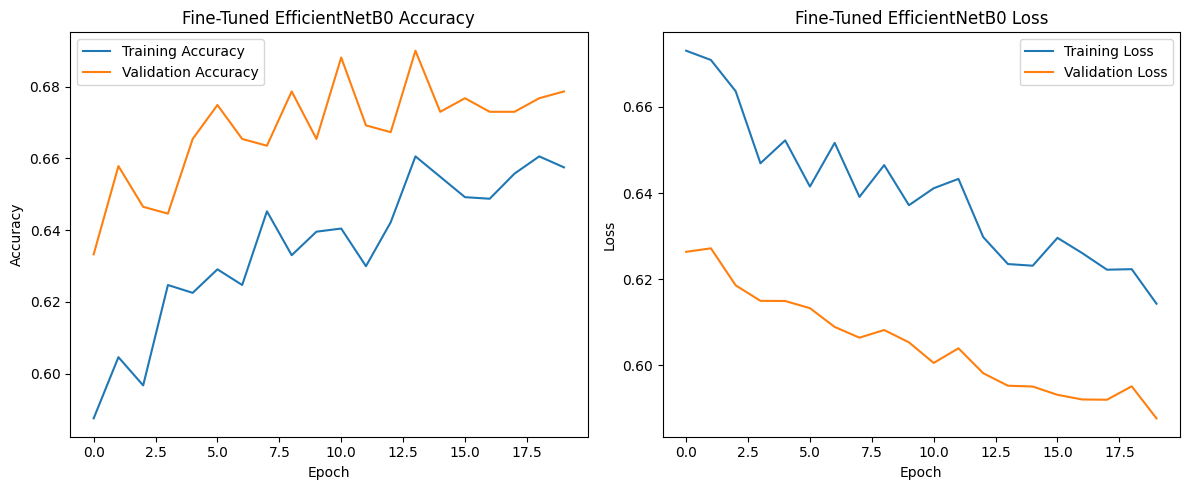

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_efficient_ft.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_efficient_ft.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Fine-Tuned EfficientNetB0 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_efficient_ft.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_efficient_ft.history['val_loss'],
    label='Validation Loss'
)

plt.title('Fine-Tuned EfficientNetB0 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
efficient_ft_results = efficient_model.evaluate(
    efficient_test_generator,
    return_dict=True
)

print("Fine-Tuned EfficientNetB0 Test Results")
print("-" * 45)

print(f"Test Loss:      {efficient_ft_results['loss']:.4f}")
print(f"Test Accuracy:  {efficient_ft_results['accuracy']:.4f}")
print(f"Test Precision: {efficient_ft_results['precision']:.4f}")
print(f"Test Recall:    {efficient_ft_results['recall']:.4f}")
print(f"Test AUC:       {efficient_ft_results['auc']:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.6645 - auc: 0.7499 - loss: 0.5944 - precision: 0.6346 - recall: 0.4975
Fine-Tuned EfficientNetB0 Test Results
---------------------------------------------
Test Loss:      0.5944
Test Accuracy:  0.6645
Test Precision: 0.6346
Test Recall:    0.4975
Test AUC:       0.7499


In [ ]:
efficient_test_generator.reset()

efficient_ft_y_prob = efficient_model.predict(
    efficient_test_generator,
    verbose=1
).ravel()

efficient_ft_y_pred = (
    efficient_ft_y_prob >= 0.5
).astype(int)

efficient_ft_y_true = efficient_test_generator.classes

15/15 ━━━━━━━━━━━━━━━━━━━━ 45s 3s/step


In [ ]:
efficient_ft_f1 = f1_score(
    efficient_ft_y_true,
    efficient_ft_y_pred
)

print(
    f"Fine-Tuned EfficientNetB0 F1-score: "
    f"{efficient_ft_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        efficient_ft_y_true,
        efficient_ft_y_pred,
        target_names=['Benign', 'Malignant'],
        digits=4
    )
)

Fine-Tuned EfficientNetB0 F1-score: 0.5577

Classification Report:
              precision    recall  f1-score   support

      Benign     0.6795    0.7881    0.7298       269
   Malignant     0.6346    0.4975    0.5577       199

    accuracy                         0.6645       468
   macro avg     0.6571    0.6428    0.6438       468
weighted avg     0.6604    0.6645    0.6566       468



In [ ]:
efficient_ft_cm = confusion_matrix(
    efficient_ft_y_true,
    efficient_ft_y_pred
)

tn, fp, fn, tp = efficient_ft_cm.ravel()

print('True Negatives :', tn)
print('False Positives:', fp)
print('False Negatives:', fn)
print('True Positives :', tp)

print("\nConfusion Matrix:")
print(efficient_ft_cm)

True Negatives : 212
False Positives: 57
False Negatives: 100
True Positives : 99

Confusion Matrix:
[[212  57]
 [100  99]]


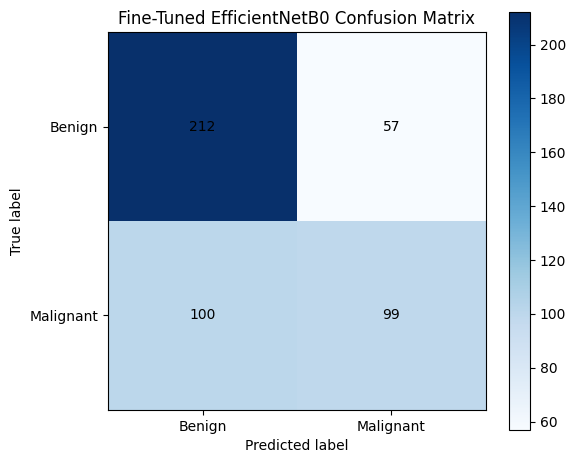

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(
    efficient_ft_cm,
    cmap='Blues'
)

plt.title('Fine-Tuned EfficientNetB0 Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.xticks(
    [0, 1],
    ['Benign', 'Malignant']
)

plt.yticks(
    [0, 1],
    ['Benign', 'Malignant']
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            efficient_ft_cm[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.tight_layout()
plt.show()

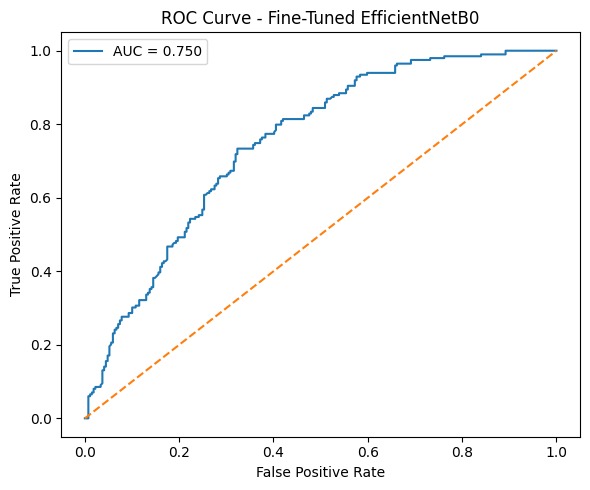

ROC-AUC Score: 0.7498552240757692


In [ ]:
efficient_ft_auc = roc_auc_score(
    efficient_ft_y_true,
    efficient_ft_y_prob
)

efficient_ft_fpr, efficient_ft_tpr, efficient_ft_thresholds = roc_curve(
    efficient_ft_y_true,
    efficient_ft_y_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    efficient_ft_fpr,
    efficient_ft_tpr,
    label=f'AUC = {efficient_ft_auc:.3f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fine-Tuned EfficientNetB0')

plt.legend()
plt.tight_layout()
plt.show()

print('ROC-AUC Score:', efficient_ft_auc)

Fine-tuning EfficientNetB0 produced modest improvements in overall performance. Accuracy increased from 0.6560 to 0.6645, recall increased from 0.4372 to 0.4975, F1-score increased from 0.5194 to 0.5577, and ROC-AUC increased from 0.7125 to 0.7499. However, false positives increased from 49 to 57, while false negatives decreased from 112 to 100. This suggests that fine-tuning improved malignant-case detection and overall discrimination, although the improvement was smaller than that observed for ResNet50.

## 14. DenseNet121 Transfer Learning

In [ ]:
from tensorflow.keras.applications.densenet import DenseNet121, preprocess_input

In [ ]:
densenet_train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

densenet_val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

densenet_train_generator = densenet_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=SEED
)

densenet_val_generator = densenet_val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

densenet_test_generator = densenet_val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 2289 validated image filenames belonging to 2 classes.
Found 529 validated image filenames belonging to 2 classes.
Found 468 validated image filenames belonging to 2 classes.


In [ ]:
densenet_base = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

densenet_base.trainable = False

print("DenseNet121 base loaded.")

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
DenseNet121 base loaded.


In [ ]:
densenet_model = tf.keras.Sequential([
    densenet_base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

densenet_model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,038,529 (26.85 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:
densenet_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [ ]:
densenet_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

     ModelCheckpoint(
        '/content/drive/MyDrive/CM3070/best_densenet121_frozen.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

history_densenet = densenet_model.fit(
    densenet_train_generator,
    validation_data=densenet_val_generator,
    epochs=20,
    callbacks=densenet_callbacks,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 312s 4s/step - accuracy: 0.4928 - auc: 0.4991 - loss: 0.9296 - precision: 0.4124 - recall: 0.5440 - val_accuracy: 0.5388 - val_auc: 0.4649 - val_loss: 0.7283 - val_precision: 0.3885 - val_recall: 0.2535 - learning_rate: 1.0000e-04
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 237s 3s/step - accuracy: 0.5116 - auc: 0.5118 - loss: 0.8843 - precision: 0.4232 - recall: 0.5111 - val_accuracy: 0.5539 - val_auc: 0.4771 - val_loss: 0.7185 - val_precision: 0.4196 - val_recall: 0.2817 - learning_rate: 1.0000e-04
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 232s 3s/step - accuracy: 0.4740 - auc: 0.4725 - loss: 0.9127 - precision: 0.3788 - recall: 0.4327 - val_accuracy: 0.5406 - val_auc: 0.4895 - val_loss: 0.7127 - val_precision: 0.4118 - val_recall: 0.3286 - learning_rate: 1.0000e-04
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 243s 3s/step - accuracy: 0.5155 - auc: 0.5152 - loss: 0.8700 - precision: 0.4272 - recall: 0.5164 - val_accuracy: 0.5822 - val_auc: 0.5034 - val_loss: 0.70

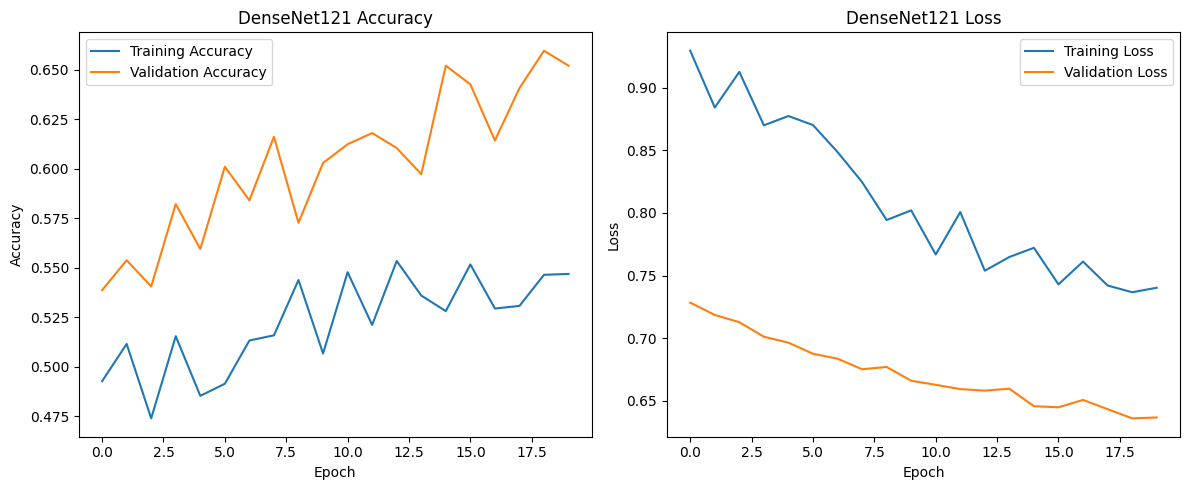

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(history_densenet.history['accuracy'], label='Training Accuracy')
plt.plot(history_densenet.history['val_accuracy'], label='Validation Accuracy')
plt.title('DenseNet121 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(history_densenet.history['loss'], label='Training Loss')
plt.plot(history_densenet.history['val_loss'], label='Validation Loss')
plt.title('DenseNet121 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
densenet_results = densenet_model.evaluate(
    densenet_test_generator,
    return_dict=True
)

print(f"Test Loss: {densenet_results['loss']:.4f}")
print(f"Test Accuracy: {densenet_results['accuracy']:.4f}")
print(f"Test Precision: {densenet_results['precision']:.4f}")
print(f"Test Recall: {densenet_results['recall']:.4f}")
print(f"Test AUC: {densenet_results['auc']:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 55s 4s/step - accuracy: 0.6581 - auc: 0.7108 - loss: 0.6312 - precision: 0.5951 - recall: 0.6131
Test Loss: 0.6312
Test Accuracy: 0.6581
Test Precision: 0.5951
Test Recall: 0.6131
Test AUC: 0.7108


In [ ]:
densenet_test_generator.reset()

densenet_y_prob = densenet_model.predict(
    densenet_test_generator
).ravel()

densenet_y_pred = (densenet_y_prob >= 0.5).astype(int)

densenet_y_true = densenet_test_generator.classes

print("Number of test samples:", len(densenet_y_true))

15/15 ━━━━━━━━━━━━━━━━━━━━ 57s 3s/step
Number of test samples: 468


In [ ]:
print(
    classification_report(
        densenet_y_true,
        densenet_y_pred,
        target_names=['Benign', 'Malignant'],
        digits=4
    )
)

              precision    recall  f1-score   support

      Benign     0.7072    0.6914    0.6992       269
   Malignant     0.5951    0.6131    0.6040       199

    accuracy                         0.6581       468
   macro avg     0.6512    0.6523    0.6516       468
weighted avg     0.6596    0.6581    0.6587       468



In [ ]:
densenet_cm = confusion_matrix(
    densenet_y_true,
    densenet_y_pred
)

tn, fp, fn, tp = densenet_cm.ravel()

print('True Negatives :', tn)
print('False Positives:', fp)
print('False Negatives:', fn)
print('True Positives :', tp)

print('\nConfusion Matrix:')
print(densenet_cm)

True Negatives : 186
False Positives: 83
False Negatives: 77
True Positives : 122

Confusion Matrix:
[[186  83]
 [ 77 122]]


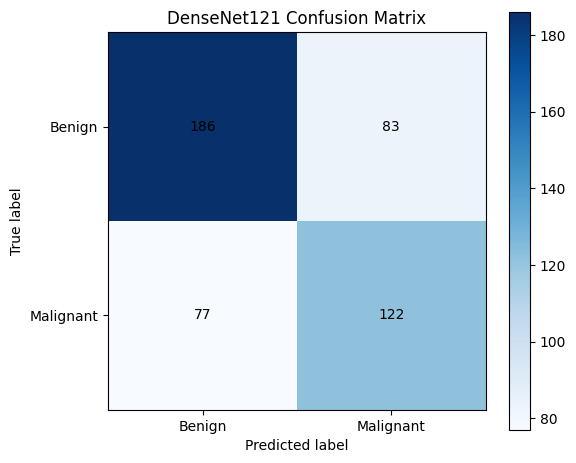

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(
    densenet_cm,
    cmap='Blues'
)

plt.title('DenseNet121 Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.xticks([0, 1], ['Benign', 'Malignant'])
plt.yticks([0, 1], ['Benign', 'Malignant'])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            densenet_cm[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.tight_layout()
plt.show()

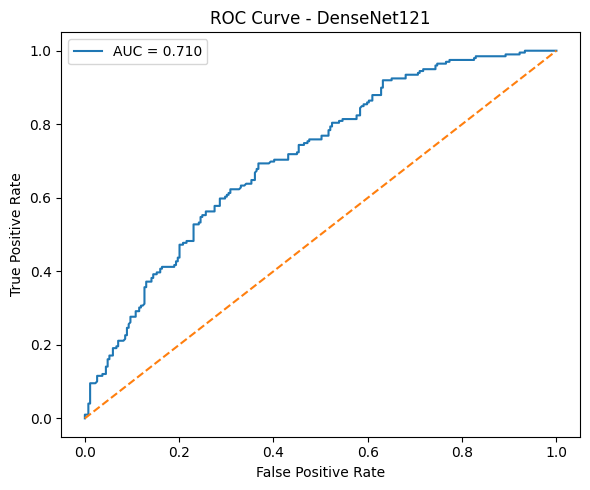

ROC-AUC Score: 0.7103267265696512


In [ ]:
densenet_auc = roc_auc_score(
    densenet_y_true,
    densenet_y_prob
)

densenet_fpr, densenet_tpr, densenet_thresholds = roc_curve(
    densenet_y_true,
    densenet_y_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    densenet_fpr,
    densenet_tpr,
    label=f'AUC = {densenet_auc:.3f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - DenseNet121')
plt.legend()

plt.tight_layout()
plt.show()

print('ROC-AUC Score:', densenet_auc)

## 14.1 DenseNet121 Fine-Tuning

Following the initial frozen transfer learning stage, the upper layers
of DenseNet121 were fine-tuned so that higher-level pretrained features
could adapt more closely to the mammography classification task.

The earlier DenseNet121 layers were kept frozen, while the final portion
of the network was made trainable. Batch Normalisation layers remained
frozen to preserve their pretrained statistics. A lower learning rate
was used during fine-tuning to reduce the risk of disrupting previously
learned ImageNet features.

In [ ]:
# ============================================================
# DenseNet121 Fine-Tuning
# Unfreeze only the final 40 layers
# ============================================================

densenet_base.trainable = True

# Freeze all layers except the final 40
for layer in densenet_base.layers[:-40]:
    layer.trainable = False

for layer in densenet_base.layers[-40:]:
    layer.trainable = True

    # Keep Batch Normalisation layers frozen
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [ ]:
print("Trainable DenseNet121 layers:")
print("-" * 50)

trainable_count = 0

for layer in densenet_base.layers:
    if layer.trainable:
        print(layer.name)
        trainable_count += 1

print("-" * 50)
print("Number of trainable DenseNet121 layers:", trainable_count)

Trainable DenseNet121 layers:
--------------------------------------------------
conv5_block11_1_relu
conv5_block11_2_conv
conv5_block11_concat
conv5_block12_0_relu
conv5_block12_1_conv
conv5_block12_1_relu
conv5_block12_2_conv
conv5_block12_concat
conv5_block13_0_relu
conv5_block13_1_conv
conv5_block13_1_relu
conv5_block13_2_conv
conv5_block13_concat
conv5_block14_0_relu
conv5_block14_1_conv
conv5_block14_1_relu
conv5_block14_2_conv
conv5_block14_concat
conv5_block15_0_relu
conv5_block15_1_conv
conv5_block15_1_relu
conv5_block15_2_conv
conv5_block15_concat
conv5_block16_0_relu
conv5_block16_1_conv
conv5_block16_1_relu
conv5_block16_2_conv
conv5_block16_concat
relu
--------------------------------------------------
Number of trainable DenseNet121 layers: 29


In [ ]:
trainable_params = np.sum([
    np.prod(weight.shape)
    for weight in densenet_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(weight.shape)
    for weight in densenet_model.non_trainable_weights
])

print(f"Trainable parameters:     {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

Trainable parameters:     816,129
Non-trainable parameters: 6,222,400


In [ ]:
densenet_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [ ]:
densenet_ft_callbacks = [

    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        '/content/drive/MyDrive/CM3070/best_densenet121_finetuned.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

FINE_TUNE_EPOCHS = 20

history_densenet_ft = densenet_model.fit(
    densenet_train_generator,
    validation_data=densenet_val_generator,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=densenet_ft_callbacks,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 303s 4s/step - accuracy: 0.5588 - auc: 0.5904 - loss: 0.7099 - precision: 0.4696 - recall: 0.5493 - val_accuracy: 0.6673 - val_auc: 0.7114 - val_loss: 0.6282 - val_precision: 0.5869 - val_recall: 0.5869 - learning_rate: 1.0000e-05
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 258s 4s/step - accuracy: 0.5640 - auc: 0.5942 - loss: 0.7079 - precision: 0.4761 - recall: 0.5801 - val_accuracy: 0.6692 - val_auc: 0.7169 - val_loss: 0.6227 - val_precision: 0.5950 - val_recall: 0.5587 - learning_rate: 1.0000e-05
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 234s 3s/step - accuracy: 0.5797 - auc: 0.6156 - loss: 0.6909 - precision: 0.4916 - recall: 0.5896 - val_accuracy: 0.6711 - val_auc: 0.7193 - val_loss: 0.6237 - val_precision: 0.5890 - val_recall: 0.6056 - learning_rate: 1.0000e-05
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 239s 3s/step - accuracy: 0.5745 - auc: 0.6069 - loss: 0.6988 - precision: 0.4860 - recall: 0.5716 - val_accuracy: 0.6711 - val_auc: 0.7207 - val_loss: 0.61

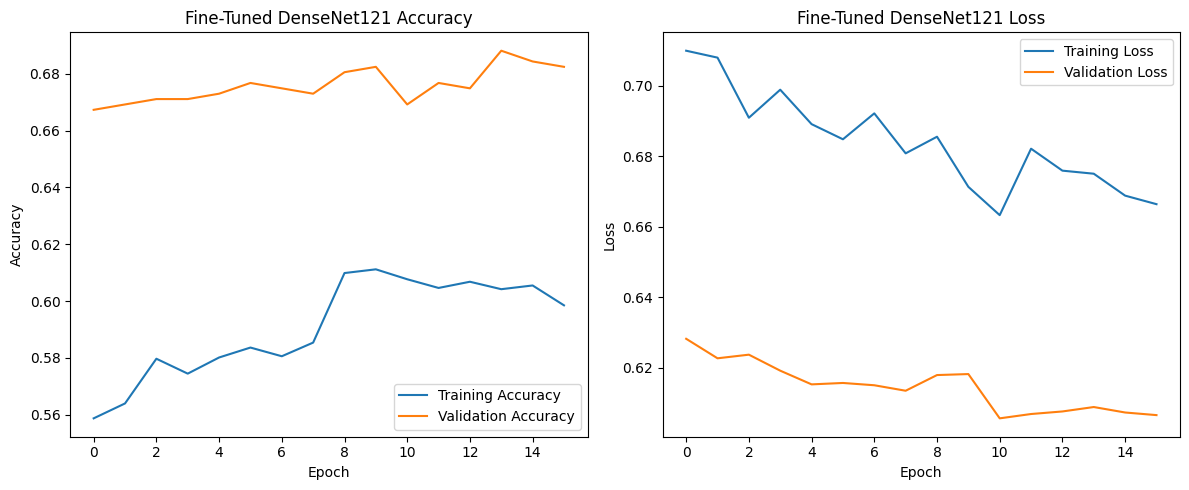

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_densenet_ft.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_densenet_ft.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Fine-Tuned DenseNet121 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_densenet_ft.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_densenet_ft.history['val_loss'],
    label='Validation Loss'
)

plt.title('Fine-Tuned DenseNet121 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
densenet_ft_results = densenet_model.evaluate(
    densenet_test_generator,
    return_dict=True
)

print("Fine-Tuned DenseNet121 Test Results")
print("-" * 45)

print(f"Test Loss:      {densenet_ft_results['loss']:.4f}")
print(f"Test Accuracy:  {densenet_ft_results['accuracy']:.4f}")
print(f"Test Precision: {densenet_ft_results['precision']:.4f}")
print(f"Test Recall:    {densenet_ft_results['recall']:.4f}")
print(f"Test AUC:       {densenet_ft_results['auc']:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 44s 3s/step - accuracy: 0.6816 - auc: 0.7462 - loss: 0.6039 - precision: 0.6812 - recall: 0.4724
Fine-Tuned DenseNet121 Test Results
---------------------------------------------
Test Loss:      0.6039
Test Accuracy:  0.6816
Test Precision: 0.6812
Test Recall:    0.4724
Test AUC:       0.7462


In [ ]:
densenet_test_generator.reset()

densenet_ft_y_prob = densenet_model.predict(
    densenet_test_generator,
    verbose=1
).ravel()

densenet_ft_y_pred = (
    densenet_ft_y_prob >= 0.5
).astype(int)

densenet_ft_y_true = densenet_test_generator.classes

15/15 ━━━━━━━━━━━━━━━━━━━━ 58s 3s/step


In [ ]:
densenet_ft_f1 = f1_score(
    densenet_ft_y_true,
    densenet_ft_y_pred
)

print(
    f"Fine-Tuned DenseNet121 F1-score: "
    f"{densenet_ft_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        densenet_ft_y_true,
        densenet_ft_y_pred,
        target_names=['Benign', 'Malignant'],
        digits=4
    )
)

Fine-Tuned DenseNet121 F1-score: 0.5579

Classification Report:
              precision    recall  f1-score   support

      Benign     0.6818    0.8364    0.7513       269
   Malignant     0.6812    0.4724    0.5579       199

    accuracy                         0.6816       468
   macro avg     0.6815    0.6544    0.6546       468
weighted avg     0.6815    0.6816    0.6690       468



In [ ]:
densenet_ft_cm = confusion_matrix(
    densenet_ft_y_true,
    densenet_ft_y_pred
)

tn, fp, fn, tp = densenet_ft_cm.ravel()

print('True Negatives :', tn)
print('False Positives:', fp)
print('False Negatives:', fn)
print('True Positives :', tp)

print("\nConfusion Matrix:")
print(densenet_ft_cm)

True Negatives : 225
False Positives: 44
False Negatives: 105
True Positives : 94

Confusion Matrix:
[[225  44]
 [105  94]]


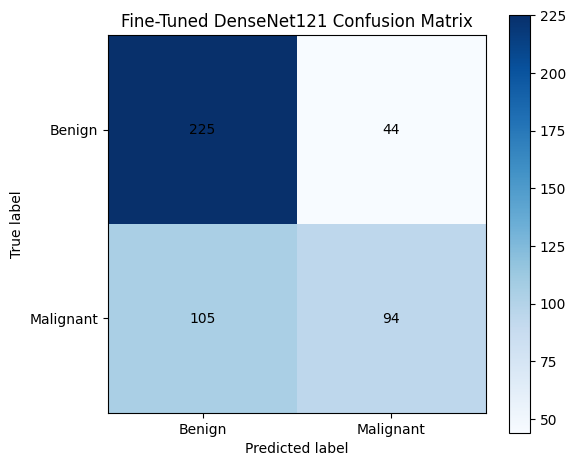

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(
    densenet_ft_cm,
    cmap='Blues'
)

plt.title('Fine-Tuned DenseNet121 Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.xticks(
    [0, 1],
    ['Benign', 'Malignant']
)

plt.yticks(
    [0, 1],
    ['Benign', 'Malignant']
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            densenet_ft_cm[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.tight_layout()
plt.show()

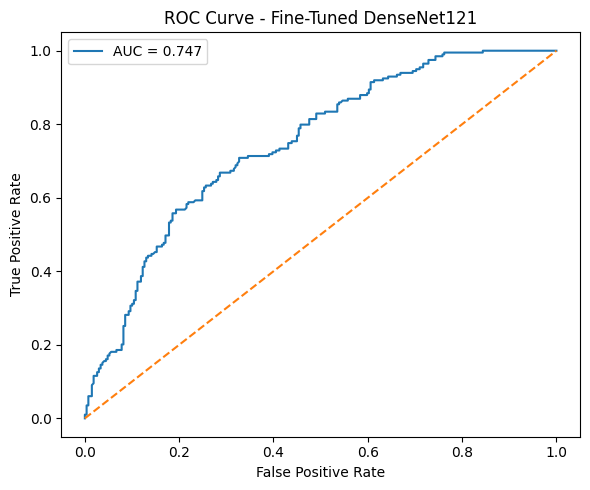

ROC-AUC Score: 0.746941024826736


In [ ]:
densenet_ft_auc = roc_auc_score(
    densenet_ft_y_true,
    densenet_ft_y_prob
)

densenet_ft_fpr, densenet_ft_tpr, densenet_ft_thresholds = roc_curve(
    densenet_ft_y_true,
    densenet_ft_y_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    densenet_ft_fpr,
    densenet_ft_tpr,
    label=f'AUC = {densenet_ft_auc:.3f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fine-Tuned DenseNet121')

plt.legend()
plt.tight_layout()
plt.show()

print('ROC-AUC Score:', densenet_ft_auc)

Fine-tuning DenseNet121 increased accuracy from 0.6581 to 0.6816, precision from 0.5951 to 0.6812, and ROC-AUC from 0.7103 to 0.7469. False positives also decreased substantially from 83 to 44. However, malignant recall decreased from 0.6131 to 0.4724, causing false negatives to increase from 77 to 105. This indicates that fine-tuning improved overall discrimination and benign-case classification but reduced sensitivity to malignant cases.

## 15. Model Comparison

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

def get_model_metrics(model_name, y_true, y_prob, threshold=0.5):
    # Convert probability predictions into class labels
    y_pred = (np.array(y_prob).ravel() >= threshold).astype(int)
    y_true = np.array(y_true).ravel()

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, np.array(y_prob).ravel()),
        "False Positives": fp,
        "False Negatives": fn
    }

In [ ]:
results = [
    get_model_metrics(
        "ResNet50 Frozen",
        resnet_y_true,
        resnet_y_prob
    ),

    get_model_metrics(
        "ResNet50 Fine-Tuned",
        resnet_ft_y_true,
        resnet_ft_y_prob
    ),

    get_model_metrics(
        "EfficientNetB0 Frozen",
        efficient_y_true,
        efficient_y_prob
    ),

    get_model_metrics(
        "EfficientNetB0 Fine-Tuned",
        efficient_ft_y_true,
        efficient_ft_y_prob
    ),

    get_model_metrics(
        "DenseNet121 Frozen",
        densenet_y_true,
        densenet_y_prob
    ),

    get_model_metrics(
        "DenseNet121 Fine-Tuned",
        densenet_ft_y_true,
        densenet_ft_y_prob
    )
]

transfer_comparison_df = pd.DataFrame(results)

transfer_comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,AUC,False Positives,False Negatives
0,ResNet50 Frozen,0.645299,0.589189,0.547739,0.567708,0.733659,76,90
1,ResNet50 Fine-Tuned,0.700855,0.639810,0.678392,0.658537,0.784564,76,64
2,EfficientNetB0 Frozen,0.655983,0.639706,0.437186,0.519403,0.712456,49,112
3,EfficientNetB0 Fine-Tuned,0.664530,0.634615,0.497487,0.557746,0.749855,57,100
4,DenseNet121 Frozen,0.658120,0.595122,0.613065,0.603960,0.710327,83,77
5,DenseNet121 Fine-Tuned,0.681624,0.681159,0.472362,0.557864,0.746941,44,105


In [ ]:
transfer_comparison_display = transfer_comparison_df.copy()

metric_columns = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'AUC'
]

transfer_comparison_display[metric_columns] = (
    transfer_comparison_display[metric_columns].round(4)
)

transfer_comparison_display

,Model,Accuracy,Precision,Recall,F1-Score,AUC,False Positives,False Negatives
0,ResNet50 Frozen,0.6453,0.5892,0.5477,0.5677,0.7337,76,90
1,ResNet50 Fine-Tuned,0.7009,0.6398,0.6784,0.6585,0.7846,76,64
2,EfficientNetB0 Frozen,0.6560,0.6397,0.4372,0.5194,0.7125,49,112
3,EfficientNetB0 Fine-Tuned,0.6645,0.6346,0.4975,0.5577,0.7499,57,100
4,DenseNet121 Frozen,0.6581,0.5951,0.6131,0.6040,0.7103,83,77
5,DenseNet121 Fine-Tuned,0.6816,0.6812,0.4724,0.5579,0.7469,44,105


Fine-tuning improved the ROC-AUC of all three transfer-learning
architectures. ResNet50 demonstrated the greatest overall benefit,
with improvements in accuracy, precision, recall, F1-score and AUC.
Its malignant recall increased from 0.5477 to 0.6784, reducing false
negatives from 90 to 64.

EfficientNetB0 also improved following fine-tuning, particularly in
recall and AUC, although the gains were smaller than those observed for
ResNet50.

DenseNet121 showed a different trade-off. Fine-tuning improved
accuracy, precision and AUC and substantially reduced false positives.
However, malignant recall decreased from 0.6131 to 0.4724, increasing
the number of false-negative predictions. These findings demonstrate
that fine-tuning did not affect all pretrained architectures uniformly.

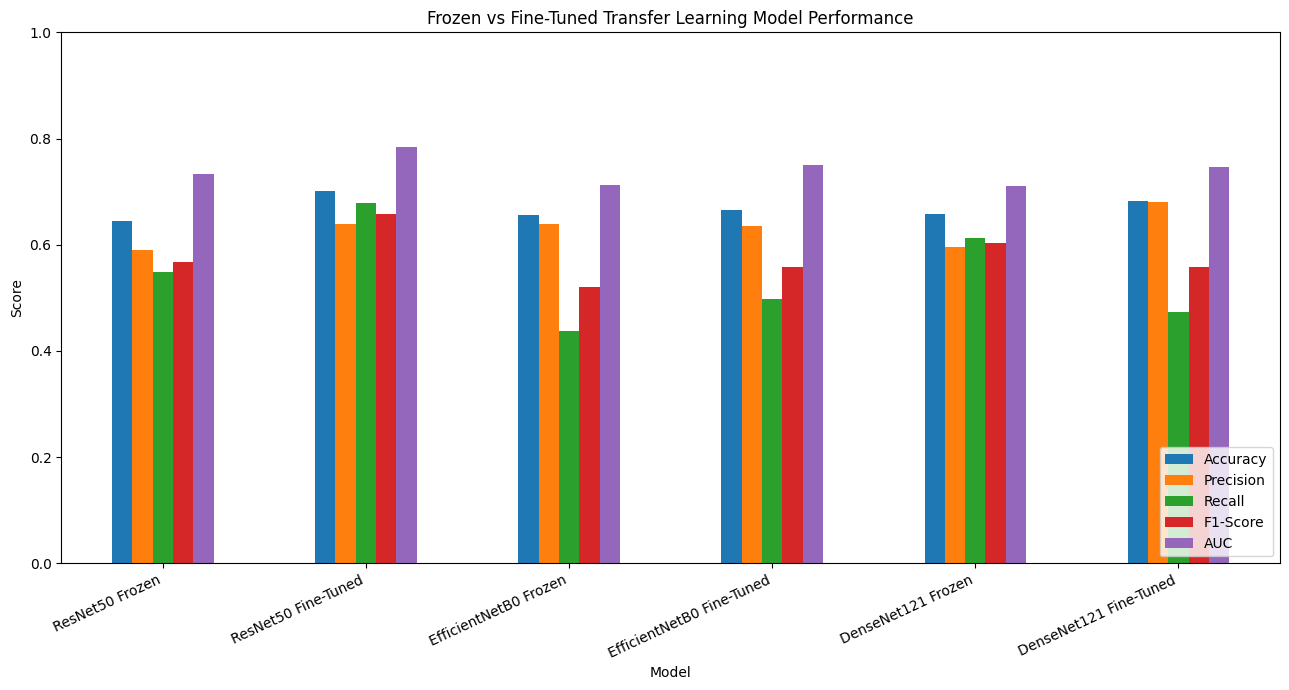

In [ ]:
metrics_to_plot = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'AUC'
]

transfer_comparison_df.set_index('Model')[metrics_to_plot].plot(
    kind='bar',
    figsize=(13, 7)
)

plt.title('Frozen vs Fine-Tuned Transfer Learning Model Performance')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=25, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

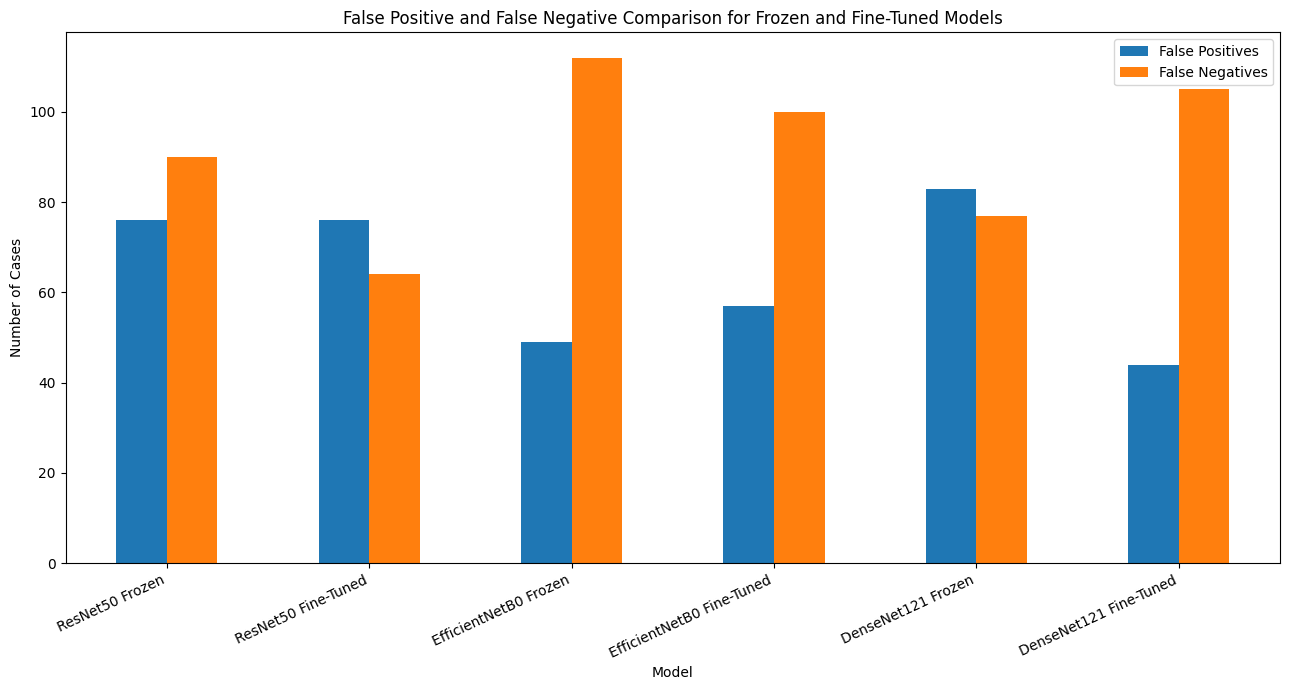

In [ ]:
transfer_comparison_df.set_index('Model')[
    ['False Positives', 'False Negatives']
].plot(
    kind='bar',
    figsize=(13, 7)
)

plt.title(
    'False Positive and False Negative Comparison '
    'for Frozen and Fine-Tuned Models'
)

plt.ylabel('Number of Cases')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

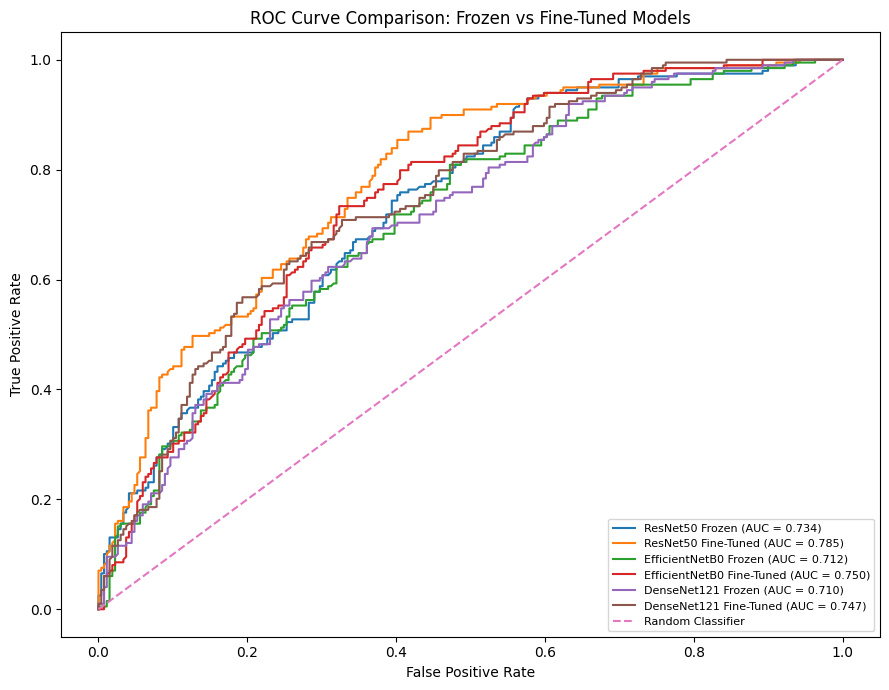

In [ ]:
plt.figure(figsize=(9, 7))

# -------------------------
# ResNet50 Frozen
# -------------------------
resnet_fpr_cmp, resnet_tpr_cmp, _ = roc_curve(
    resnet_y_true,
    resnet_y_prob
)

resnet_auc_cmp = roc_auc_score(
    resnet_y_true,
    resnet_y_prob
)

plt.plot(
    resnet_fpr_cmp,
    resnet_tpr_cmp,
    label=f'ResNet50 Frozen (AUC = {resnet_auc_cmp:.3f})'
)


# -------------------------
# ResNet50 Fine-Tuned
# -------------------------
resnet_ft_fpr_cmp, resnet_ft_tpr_cmp, _ = roc_curve(
    resnet_ft_y_true,
    resnet_ft_y_prob
)

resnet_ft_auc_cmp = roc_auc_score(
    resnet_ft_y_true,
    resnet_ft_y_prob
)

plt.plot(
    resnet_ft_fpr_cmp,
    resnet_ft_tpr_cmp,
    label=f'ResNet50 Fine-Tuned (AUC = {resnet_ft_auc_cmp:.3f})'
)


# -------------------------
# EfficientNetB0 Frozen
# -------------------------
efficient_fpr_cmp, efficient_tpr_cmp, _ = roc_curve(
    efficient_y_true,
    efficient_y_prob
)

efficient_auc_cmp = roc_auc_score(
    efficient_y_true,
    efficient_y_prob
)

plt.plot(
    efficient_fpr_cmp,
    efficient_tpr_cmp,
    label=f'EfficientNetB0 Frozen (AUC = {efficient_auc_cmp:.3f})'
)


# -------------------------
# EfficientNetB0 Fine-Tuned
# -------------------------
efficient_ft_fpr_cmp, efficient_ft_tpr_cmp, _ = roc_curve(
    efficient_ft_y_true,
    efficient_ft_y_prob
)

efficient_ft_auc_cmp = roc_auc_score(
    efficient_ft_y_true,
    efficient_ft_y_prob
)

plt.plot(
    efficient_ft_fpr_cmp,
    efficient_ft_tpr_cmp,
    label=f'EfficientNetB0 Fine-Tuned (AUC = {efficient_ft_auc_cmp:.3f})'
)


# -------------------------
# DenseNet121 Frozen
# -------------------------
densenet_fpr_cmp, densenet_tpr_cmp, _ = roc_curve(
    densenet_y_true,
    densenet_y_prob
)

densenet_auc_cmp = roc_auc_score(
    densenet_y_true,
    densenet_y_prob
)

plt.plot(
    densenet_fpr_cmp,
    densenet_tpr_cmp,
    label=f'DenseNet121 Frozen (AUC = {densenet_auc_cmp:.3f})'
)


# -------------------------
# DenseNet121 Fine-Tuned
# -------------------------
densenet_ft_fpr_cmp, densenet_ft_tpr_cmp, _ = roc_curve(
    densenet_ft_y_true,
    densenet_ft_y_prob
)

densenet_ft_auc_cmp = roc_auc_score(
    densenet_ft_y_true,
    densenet_ft_y_prob
)

plt.plot(
    densenet_ft_fpr_cmp,
    densenet_ft_tpr_cmp,
    label=f'DenseNet121 Fine-Tuned (AUC = {densenet_ft_auc_cmp:.3f})'
)


# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Frozen vs Fine-Tuned Models')

plt.legend(
    loc='lower right',
    fontsize=8
)

plt.tight_layout()
plt.show()

In [ ]:
fine_tuning_change = pd.DataFrame({
    'Model': [
        'ResNet50',
        'EfficientNetB0',
        'DenseNet121'
    ],

    'Accuracy Change': [
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'ResNet50 Fine-Tuned',
            'Accuracy'
        ].values[0]
        -
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'ResNet50 Frozen',
            'Accuracy'
        ].values[0],

        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'EfficientNetB0 Fine-Tuned',
            'Accuracy'
        ].values[0]
        -
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'EfficientNetB0 Frozen',
            'Accuracy'
        ].values[0],

        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'DenseNet121 Fine-Tuned',
            'Accuracy'
        ].values[0]
        -
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'DenseNet121 Frozen',
            'Accuracy'
        ].values[0]
    ],

    'Recall Change': [
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'ResNet50 Fine-Tuned',
            'Recall'
        ].values[0]
        -
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'ResNet50 Frozen',
            'Recall'
        ].values[0],

        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'EfficientNetB0 Fine-Tuned',
            'Recall'
        ].values[0]
        -
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'EfficientNetB0 Frozen',
            'Recall'
        ].values[0],

        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'DenseNet121 Fine-Tuned',
            'Recall'
        ].values[0]
        -
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'DenseNet121 Frozen',
            'Recall'
        ].values[0]
    ],

    'AUC Change': [
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'ResNet50 Fine-Tuned',
            'AUC'
        ].values[0]
        -
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'ResNet50 Frozen',
            'AUC'
        ].values[0],

        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'EfficientNetB0 Fine-Tuned',
            'AUC'
        ].values[0]
        -
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'EfficientNetB0 Frozen',
            'AUC'
        ].values[0],

        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'DenseNet121 Fine-Tuned',
            'AUC'
        ].values[0]
        -
        transfer_comparison_df.loc[
            transfer_comparison_df['Model'] == 'DenseNet121 Frozen',
            'AUC'
        ].values[0]
    ]
})

fine_tuning_change.round(4)

,Model,Accuracy Change,Recall Change,AUC Change
0,ResNet50,0.0556,0.1307,0.0509
1,EfficientNetB0,0.0085,0.0603,0.0374
2,DenseNet121,0.0235,-0.1407,0.0366


## 16. Classification Threshold Analysis

The default classification threshold of 0.5 may not provide the
optimal balance between malignant-case sensitivity and false-positive
predictions. As false-negative predictions are particularly important
in breast cancer screening, different classification thresholds were
evaluated using the strongest model, the fine-tuned ResNet50.

In [ ]:
# ============================================================
# Threshold Selection Using Validation Set
# Fine-Tuned ResNet50
# ============================================================

resnet_val_generator.reset()

resnet_ft_val_y_prob = resnet_model.predict(
    resnet_val_generator,
    verbose=1
).ravel()

resnet_ft_val_y_true = resnet_val_generator.classes

print("Validation samples:", len(resnet_ft_val_y_true))

17/17 ━━━━━━━━━━━━━━━━━━━━ 44s 3s/step
Validation samples: 529


In [ ]:
thresholds = np.arange(0.30, 0.71, 0.05)

val_threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        resnet_ft_val_y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        resnet_ft_val_y_true,
        y_pred_threshold
    ).ravel()

    accuracy = accuracy_score(
        resnet_ft_val_y_true,
        y_pred_threshold
    )

    precision = precision_score(
        resnet_ft_val_y_true,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        resnet_ft_val_y_true,
        y_pred_threshold
    )

    f1 = f1_score(
        resnet_ft_val_y_true,
        y_pred_threshold
    )

    specificity = tn / (tn + fp)

    youden_j = recall + specificity - 1

    val_threshold_results.append({
        'Threshold': threshold,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'Specificity': specificity,
        'F1-Score': f1,
        'Youden_J': youden_j,
        'False Positives': fp,
        'False Negatives': fn
    })

In [ ]:
val_threshold_df = pd.DataFrame(
    val_threshold_results
)

val_threshold_display = val_threshold_df.copy()

metric_columns = [
    'Threshold',
    'Accuracy',
    'Precision',
    'Recall',
    'Specificity',
    'F1-Score',
    'Youden_J'
]

val_threshold_display[metric_columns] = (
    val_threshold_display[metric_columns].round(4)
)

val_threshold_display

,Threshold,Accuracy,Precision,Recall,Specificity,F1-Score,Youden_J,False Positives,False Negatives
0,0.30,0.6276,0.5209,0.9343,0.4209,0.6689,0.3552,183,14
1,0.35,0.6465,0.5359,0.9108,0.4684,0.6748,0.3792,168,19
2,0.40,0.6616,0.5515,0.8545,0.5316,0.6703,0.3861,148,31
3,0.45,0.6673,0.5623,0.7840,0.5886,0.6549,0.3726,130,46
4,0.50,0.6749,0.5756,0.7324,0.6361,0.6446,0.3685,115,57
5,0.55,0.6749,0.5823,0.6808,0.6709,0.6277,0.3516,104,68
6,0.60,0.6862,0.6083,0.6197,0.7310,0.6140,0.3507,85,81
7,0.65,0.6805,0.6250,0.5164,0.7911,0.5656,0.3076,66,103
8,0.70,0.6975,0.6853,0.4601,0.8576,0.5506,0.3177,45,115


In [ ]:
best_val_f1_row = val_threshold_df.loc[
    val_threshold_df['F1-Score'].idxmax()
]

best_val_youden_row = val_threshold_df.loc[
    val_threshold_df['Youden_J'].idxmax()
]

print("Best validation threshold using F1-score:")
print(best_val_f1_row)

print("\nBest validation threshold using Youden's J:")
print(best_val_youden_row)

Best validation threshold using F1-score:
Threshold            0.350000
Accuracy             0.646503
Precision            0.535912
Recall               0.910798
Specificity          0.468354
F1-Score             0.674783
Youden_J             0.379153
False Positives    168.000000
False Negatives     19.000000
Name: 1, dtype: float64

Best validation threshold using Youden's J:
Threshold            0.400000
Accuracy             0.661626
Precision            0.551515
Recall               0.854460
Specificity          0.531646
F1-Score             0.670350
Youden_J             0.386106
False Positives    148.000000
False Negatives     31.000000
Name: 2, dtype: float64


In [ ]:
SELECTED_THRESHOLD = 0.40

print(
    f"Selected classification threshold: "
    f"{SELECTED_THRESHOLD:.2f}"
)

Selected classification threshold: 0.40


### Validation-Based Threshold Selection

Classification thresholds from 0.30 to 0.70 were evaluated using the
validation dataset. Threshold selection was performed without reference
to the test dataset to preserve the independence of the final evaluation.

A threshold of 0.40 was selected because it achieved the highest
Youden's J statistic, providing the best balance between sensitivity
and specificity among the evaluated thresholds. At this threshold,
validation sensitivity was 0.8545 and specificity was 0.5316.

In [ ]:
# ============================================================
# Final Test Evaluation
# Validation-selected threshold = 0.40
# ============================================================

SELECTED_THRESHOLD = 0.40

resnet_final_y_pred = (
    resnet_ft_y_prob >= SELECTED_THRESHOLD
).astype(int)

final_cm = confusion_matrix(
    resnet_ft_y_true,
    resnet_final_y_pred
)

tn, fp, fn, tp = final_cm.ravel()

final_accuracy = accuracy_score(
    resnet_ft_y_true,
    resnet_final_y_pred
)

final_precision = precision_score(
    resnet_ft_y_true,
    resnet_final_y_pred,
    zero_division=0
)

final_recall = recall_score(
    resnet_ft_y_true,
    resnet_final_y_pred
)

final_specificity = tn / (tn + fp)

final_f1 = f1_score(
    resnet_ft_y_true,
    resnet_final_y_pred
)

# AUC does not depend on the classification threshold
final_auc = roc_auc_score(
    resnet_ft_y_true,
    resnet_ft_y_prob
)

print("FINAL RESNET50 TEST RESULTS")
print("=" * 45)
print(f"Selected Threshold: {SELECTED_THRESHOLD:.2f}")
print(f"Accuracy:           {final_accuracy:.4f}")
print(f"Precision:          {final_precision:.4f}")
print(f"Recall/Sensitivity: {final_recall:.4f}")
print(f"Specificity:        {final_specificity:.4f}")
print(f"F1-Score:           {final_f1:.4f}")
print(f"AUC:                {final_auc:.4f}")

print("\nConfusion Matrix")
print("-" * 45)
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")

FINAL RESNET50 TEST RESULTS
Selected Threshold: 0.40
Accuracy:           0.6987
Precision:          0.6124
Recall/Sensitivity: 0.7940
Specificity:        0.6283
F1-Score:           0.6915
AUC:                0.7846

Confusion Matrix
---------------------------------------------
True Negatives:  169
False Positives: 100
False Negatives: 41
True Positives:  158


In [ ]:
print("\nClassification Report:")

print(
    classification_report(
        resnet_ft_y_true,
        resnet_final_y_pred,
        target_names=['Benign', 'Malignant'],
        digits=4
    )
)


Classification Report:
              precision    recall  f1-score   support

      Benign     0.8048    0.6283    0.7056       269
   Malignant     0.6124    0.7940    0.6915       199

    accuracy                         0.6987       468
   macro avg     0.7086    0.7111    0.6986       468
weighted avg     0.7230    0.6987    0.6996       468



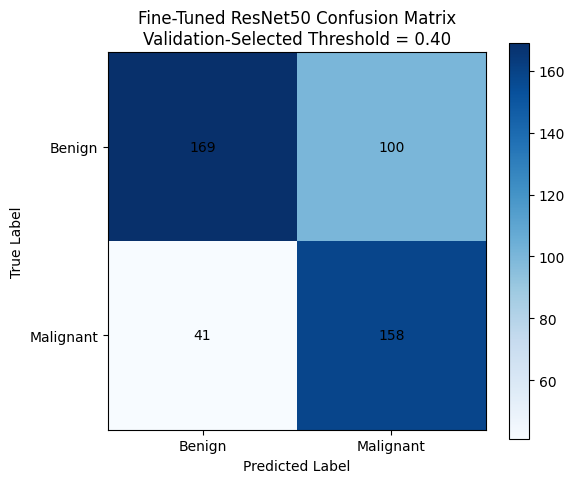

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(
    final_cm,
    cmap='Blues'
)

plt.title(
    'Fine-Tuned ResNet50 Confusion Matrix\n'
    'Validation-Selected Threshold = 0.40'
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.xticks(
    [0, 1],
    ['Benign', 'Malignant']
)

plt.yticks(
    [0, 1],
    ['Benign', 'Malignant']
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            final_cm[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
# Predictions at default threshold
y_pred_050 = (
    resnet_ft_y_prob >= 0.50
).astype(int)

tn_050, fp_050, fn_050, tp_050 = confusion_matrix(
    resnet_ft_y_true,
    y_pred_050
).ravel()

specificity_050 = tn_050 / (tn_050 + fp_050)

threshold_final_comparison = pd.DataFrame({
    'Threshold': ['Default (0.50)', 'Selected (0.40)'],

    'Accuracy': [
        accuracy_score(resnet_ft_y_true, y_pred_050),
        final_accuracy
    ],

    'Precision': [
        precision_score(resnet_ft_y_true, y_pred_050),
        final_precision
    ],

    'Recall / Sensitivity': [
        recall_score(resnet_ft_y_true, y_pred_050),
        final_recall
    ],

    'Specificity': [
        specificity_050,
        final_specificity
    ],

    'F1-Score': [
        f1_score(resnet_ft_y_true, y_pred_050),
        final_f1
    ],

    'False Positives': [
        fp_050,
        fp
    ],

    'False Negatives': [
        fn_050,
        fn
    ]
})

threshold_final_comparison.round(4)

,Threshold,Accuracy,Precision,Recall / Sensitivity,Specificity,F1-Score,False Positives,False Negatives
0,Default (0.50),0.7009,0.6398,0.6784,0.7175,0.6585,76,64
1,Selected (0.40),0.6987,0.6124,0.7940,0.6283,0.6915,100,41


The default classification threshold of 0.50 was compared with the validation-selected threshold of 0.40 for the fine-tuned ResNet50 model. Reducing the threshold increased malignant recall from 0.6784 to 0.7940 and reduced false negatives from 64 to 41. However, this improvement was accompanied by an increase in false positives from 76 to 100 and a reduction in specificity from 0.7175 to 0.6283. The F1-score improved from 0.6585 to 0.6915, while overall accuracy remained similar. These results demonstrate the trade-off between sensitivity and specificity when adjusting the classification threshold. For breast cancer detection, the increased sensitivity is particularly relevant because it reduces the number of malignant cases incorrectly classified as benign.

### **17. False Positive and False Negative Analysis**

In [ ]:
# ============================================================
# 17. False Positive and False Negative Analysis
# Fine-Tuned ResNet50
# Validation-selected threshold = 0.40
# ============================================================

SELECTED_THRESHOLD = 0.40

# Get the true labels directly from the test generator
error_y_true = np.array(
    resnet_test_generator.classes
).astype(int).ravel()

# Use the final ResNet50 predicted probabilities
error_y_prob = np.array(
    resnet_ft_y_prob
).astype(float).ravel()

# Sanity check
print("Number of true labels:", len(error_y_true))
print("Number of probabilities:", len(error_y_prob))

print("True label values:", np.unique(error_y_true))

# Apply validation-selected threshold
error_y_pred = (
    error_y_prob >= SELECTED_THRESHOLD
).astype(int)

# Calculate confusion matrix
error_cm = confusion_matrix(
    error_y_true,
    error_y_pred
)

print("\nConfusion Matrix:")
print(error_cm)

tn, fp, fn, tp = error_cm.ravel()

print("\nTrue Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

# Find exact locations of errors
fp_indices = np.where(
    (error_y_true == 0) &
    (error_y_pred == 1)
)[0]

fn_indices = np.where(
    (error_y_true == 1) &
    (error_y_pred == 0)
)[0]

print("\nFalse Positive cases:", len(fp_indices))
print("False Negative cases:", len(fn_indices))

Number of true labels: 468
Number of probabilities: 468
True label values: [0 1]

Confusion Matrix:
[[169 100]
 [ 41 158]]

True Negatives : 169
False Positives: 100
False Negatives: 41
True Positives : 158

False Positive cases: 100
False Negative cases: 41


In [ ]:
# Get image paths in exactly the same order as the test generator
test_filepaths = np.array(
    resnet_test_generator.filepaths
)

# False-positive dataframe
fp_df = pd.DataFrame({
    'image_path': test_filepaths[fp_indices],
    'true_label': 'Benign',
    'predicted_label': 'Malignant',
    'malignant_probability': error_y_prob[fp_indices]
})

# False-negative dataframe
fn_df = pd.DataFrame({
    'image_path': test_filepaths[fn_indices],
    'true_label': 'Malignant',
    'predicted_label': 'Benign',
    'malignant_probability': error_y_prob[fn_indices]
})

print("False Positives:")
display(fp_df.head())

print("\nFalse Negatives:")
display(fn_df.head())

False Positives:


,image_path,true_label,predicted_label,malignant_probability
0,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Benign,Malignant,0.480138
1,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Benign,Malignant,0.554948
2,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Benign,Malignant,0.507127
3,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Benign,Malignant,0.453676
4,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Benign,Malignant,0.646976



False Negatives:


,image_path,true_label,predicted_label,malignant_probability
0,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Malignant,Benign,0.257757
1,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Malignant,Benign,0.279723
2,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Malignant,Benign,0.337375
3,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Malignant,Benign,0.190201
4,/content/drive/MyDrive/CM3070/CBIS-DDSM/jpeg/1...,Malignant,Benign,0.396991


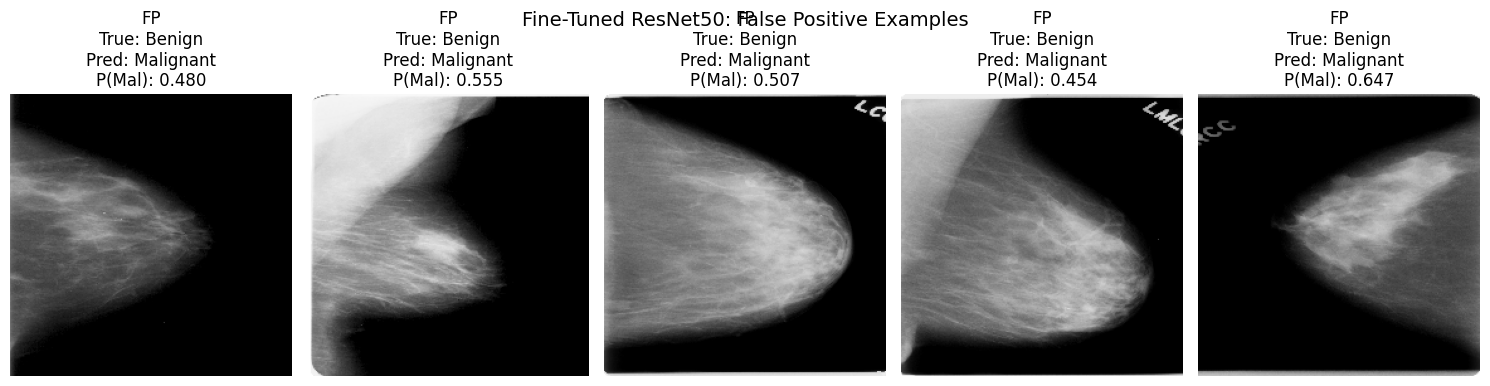

In [ ]:
# ============================================================
# Display False Positive Examples
# ============================================================

NUM_EXAMPLES = 5

plt.figure(figsize=(15, 4))

for i, idx in enumerate(fp_indices[:NUM_EXAMPLES]):

    image_path = test_filepaths[idx]

    # Load image
    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    plt.subplot(1, NUM_EXAMPLES, i + 1)

    # Display original image
    plt.imshow(img, cmap='gray')
    plt.axis('off')

    probability = error_y_prob[idx]

    plt.title(
        f"FP\n"
        f"True: Benign\n"
        f"Pred: Malignant\n"
        f"P(Mal): {probability:.3f}"
    )

plt.suptitle(
    "Fine-Tuned ResNet50: False Positive Examples",
    fontsize=14
)

plt.tight_layout()
plt.show()

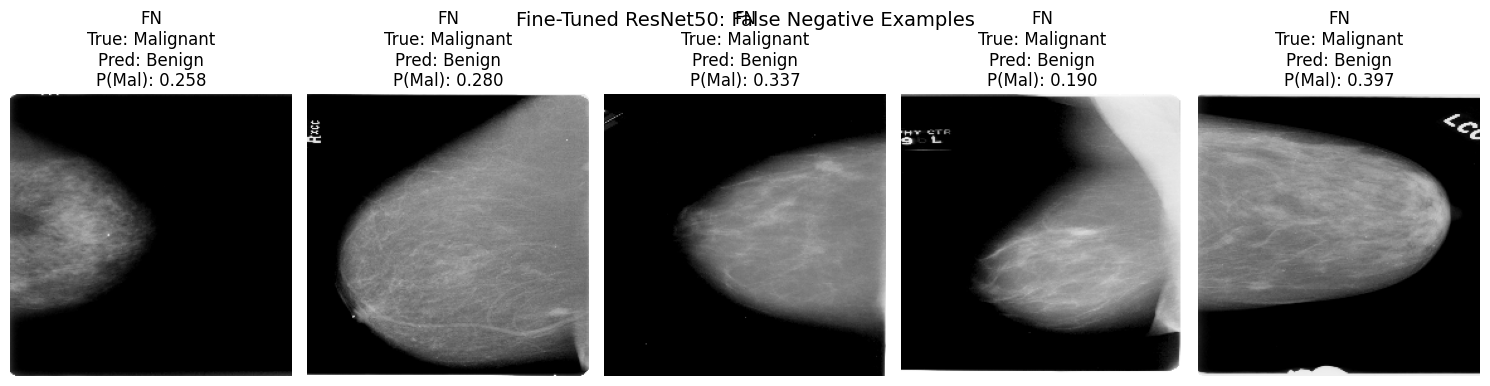

In [ ]:
# ============================================================
# Display False Negative Examples
# ============================================================

NUM_EXAMPLES = 5

plt.figure(figsize=(15, 4))

for i, idx in enumerate(fn_indices[:NUM_EXAMPLES]):

    image_path = test_filepaths[idx]

    # Load image
    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    plt.subplot(1, NUM_EXAMPLES, i + 1)

    # Display original image
    plt.imshow(img, cmap='gray')
    plt.axis('off')

    probability = error_y_prob[idx]

    plt.title(
        f"FN\n"
        f"True: Malignant\n"
        f"Pred: Benign\n"
        f"P(Mal): {probability:.3f}"
    )

plt.suptitle(
    "Fine-Tuned ResNet50: False Negative Examples",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Representative False Positive / False Negative Examples
# ============================================================

SELECTED_THRESHOLD = 0.40

# ------------------------------------------------------------
# Select representative False Positives
# ------------------------------------------------------------

fp_probs = error_y_prob[fp_indices]

# Sort FP cases by malignant probability
fp_sorted = fp_indices[np.argsort(fp_probs)]

# FP probabilities are >= 0.40
# Lowest = closest to threshold
# Middle = moderate
# Highest = most confident incorrect malignant prediction
fp_representative = [
    fp_sorted[0],
    fp_sorted[len(fp_sorted) // 2],
    fp_sorted[-1]
]


# ------------------------------------------------------------
# Select representative False Negatives
# ------------------------------------------------------------

fn_probs = error_y_prob[fn_indices]

# Sort FN cases by malignant probability
fn_sorted = fn_indices[np.argsort(fn_probs)]

# FN probabilities are < 0.40
# Highest = closest to threshold
# Middle = moderate
# Lowest = most confident incorrect benign prediction
fn_representative = [
    fn_sorted[-1],
    fn_sorted[len(fn_sorted) // 2],
    fn_sorted[0]
]

print("Representative FP probabilities:")
for idx in fp_representative:
    print(f"{error_y_prob[idx]:.4f}")

print("\nRepresentative FN probabilities:")
for idx in fn_representative:
    print(f"{error_y_prob[idx]:.4f}")

Representative FP probabilities:
0.4028
0.6023
0.9050

Representative FN probabilities:
0.3980
0.3210
0.0548


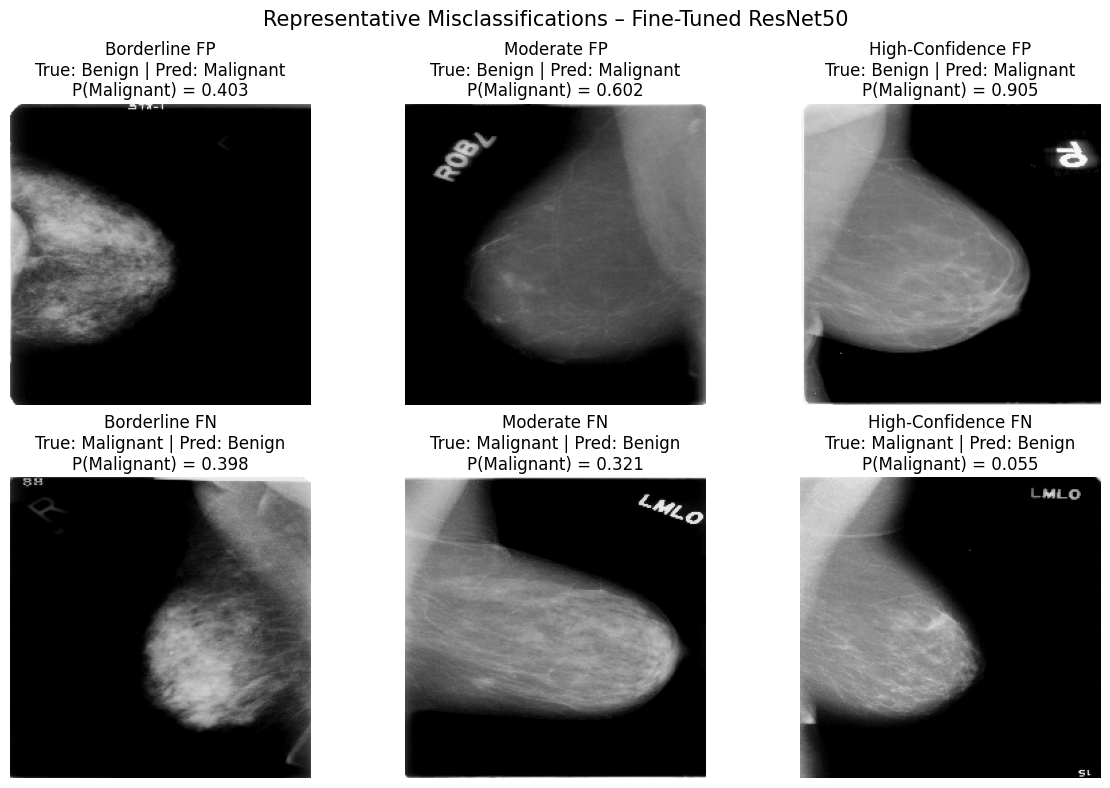

In [ ]:
# ============================================================
# Display Representative Misclassification Examples
# ============================================================

plt.figure(figsize=(12, 8))

# ------------------------------------------------------------
# False Positives
# ------------------------------------------------------------

fp_labels = [
    "Borderline FP",
    "Moderate FP",
    "High-Confidence FP"
]

for i, idx in enumerate(fp_representative):

    image_path = test_filepaths[idx]

    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    plt.subplot(2, 3, i + 1)

    plt.imshow(img, cmap='gray')
    plt.axis('off')

    plt.title(
        f"{fp_labels[i]}\n"
        f"True: Benign | Pred: Malignant\n"
        f"P(Malignant) = {error_y_prob[idx]:.3f}"
    )


# ------------------------------------------------------------
# False Negatives
# ------------------------------------------------------------

fn_labels = [
    "Borderline FN",
    "Moderate FN",
    "High-Confidence FN"
]

for i, idx in enumerate(fn_representative):

    image_path = test_filepaths[idx]

    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    plt.subplot(2, 3, i + 4)

    plt.imshow(img, cmap='gray')
    plt.axis('off')

    plt.title(
        f"{fn_labels[i]}\n"
        f"True: Malignant | Pred: Benign\n"
        f"P(Malignant) = {error_y_prob[idx]:.3f}"
    )

plt.suptitle(
    "Representative Misclassifications – Fine-Tuned ResNet50",
    fontsize=15
)

plt.tight_layout()
plt.show()

The final fine-tuned ResNet50 produced 100 false-positive and 41 false-negative predictions at the validation-selected threshold of 0.40. Representative examples showed that some misclassifications occurred close to the decision threshold, while others were associated with probabilities substantially further from the threshold, indicating more confident errors. False-negative cases are particularly important because they represent malignant mammograms incorrectly classified as benign. However, the mammogram images alone are insufficient to determine the exact visual cause of each model error without additional lesion-level interpretation or explainability analysis.

## 18. Grad-CAM Explainability

Grad-CAM was applied to the final fine-tuned ResNet50 model to provide
visual insight into the image regions contributing to its predictions.

The analysis was performed on representative true-positive, true-negative,
false-positive and false-negative mammograms. The resulting heatmaps
highlight regions that had a stronger influence on the model prediction.

Grad-CAM does not provide a clinical explanation or confirm that highlighted
regions correspond to actual lesions. Instead, it provides a visual indication
of where the neural network focused when generating its prediction.

In [ ]:
# Check the last layers of the ResNet50 backbone

for layer in resnet_base.layers[-15:]:
    print(layer.name, layer.output.shape)

conv5_block2_2_relu (None, 7, 7, 512)
conv5_block2_3_conv (None, 7, 7, 2048)
conv5_block2_3_bn (None, 7, 7, 2048)
conv5_block2_add (None, 7, 7, 2048)
conv5_block2_out (None, 7, 7, 2048)
conv5_block3_1_conv (None, 7, 7, 512)
conv5_block3_1_bn (None, 7, 7, 512)
conv5_block3_1_relu (None, 7, 7, 512)
conv5_block3_2_conv (None, 7, 7, 512)
conv5_block3_2_bn (None, 7, 7, 512)
conv5_block3_2_relu (None, 7, 7, 512)
conv5_block3_3_conv (None, 7, 7, 2048)
conv5_block3_3_bn (None, 7, 7, 2048)
conv5_block3_add (None, 7, 7, 2048)
conv5_block3_out (None, 7, 7, 2048)


In [ ]:
# ============================================================
# Grad-CAM Function for Fine-Tuned ResNet50
# ============================================================

import tensorflow as tf
import numpy as np

LAST_CONV_LAYER = 'conv5_block3_out'


def make_gradcam_heatmap(img_array):

    # Model returning:
    # 1. Last convolutional feature maps
    # 2. Final output of ResNet50 backbone
    grad_model = tf.keras.Model(
        inputs=resnet_base.input,
        outputs=[
            resnet_base.get_layer(LAST_CONV_LAYER).output,
            resnet_base.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, base_outputs = grad_model(
            img_array,
            training=False
        )

        # Pass ResNet output through classification head
        x = resnet_model.layers[1](
            base_outputs
        )

        x = resnet_model.layers[2](
            x,
            training=False
        )

        predictions = resnet_model.layers[3](
            x
        )

        # Binary malignant prediction
        loss = predictions[:, 0]

    # Gradient of malignant score
    # with respect to final convolutional feature maps
    grads = tape.gradient(
        loss,
        conv_outputs
    )

    # Average gradients across spatial dimensions
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    # Weight each feature map
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    # Keep positive contributions
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalise to 0–1
    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap = heatmap / max_value

    return heatmap.numpy()

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input


def prepare_resnet_image(image_path):

    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(
        img
    )

    img_batch = np.expand_dims(
        img_array,
        axis=0
    )

    img_batch = preprocess_input(
        img_batch
    )

    return img, img_batch

In [ ]:
import matplotlib.pyplot as plt


def display_gradcam(
    image_path,
    true_label,
    predicted_label,
    probability
):

    # Prepare image
    original_img, img_array = prepare_resnet_image(
        image_path
    )

    # Generate Grad-CAM
    heatmap = make_gradcam_heatmap(
        img_array
    )

    # Convert original image to numpy
    original_array = np.array(
        original_img
    )

    # Resize heatmap to mammogram size
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # Plot
    plt.figure(figsize=(12, 4))

    # Original
    plt.subplot(1, 3, 1)

    plt.imshow(
        original_array,
        cmap='gray'
    )

    plt.title("Original Mammogram")
    plt.axis('off')


    # Heatmap
    plt.subplot(1, 3, 2)

    plt.imshow(
        heatmap_resized,
        cmap='jet'
    )

    plt.title("Grad-CAM Heatmap")
    plt.axis('off')


    # Overlay
    plt.subplot(1, 3, 3)

    plt.imshow(
        original_array,
        cmap='gray'
    )

    plt.imshow(
        heatmap_resized,
        cmap='jet',
        alpha=0.40
    )

    plt.title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}\n"
        f"P(Malignant): {probability:.3f}"
    )

    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# Identify prediction categories
# ============================================================

tp_indices = np.where(
    (error_y_true == 1) &
    (error_y_pred == 1)
)[0]

tn_indices = np.where(
    (error_y_true == 0) &
    (error_y_pred == 0)
)[0]

fp_indices = np.where(
    (error_y_true == 0) &
    (error_y_pred == 1)
)[0]

fn_indices = np.where(
    (error_y_true == 1) &
    (error_y_pred == 0)
)[0]

print("True Positives :", len(tp_indices))
print("True Negatives :", len(tn_indices))
print("False Positives:", len(fp_indices))
print("False Negatives:", len(fn_indices))

True Positives : 158
True Negatives : 169
False Positives: 100
False Negatives: 41


In [ ]:
# ============================================================
# Select Representative Cases for Grad-CAM
# ============================================================

# True Positive:
# choose the malignant case with the highest malignant probability
tp_selected = tp_indices[
    np.argmax(error_y_prob[tp_indices])
]

# True Negative:
# choose the benign case with the lowest malignant probability
tn_selected = tn_indices[
    np.argmin(error_y_prob[tn_indices])
]

# False Positive:
# choose the benign case with the highest malignant probability
fp_selected = fp_indices[
    np.argmax(error_y_prob[fp_indices])
]

# False Negative:
# choose the malignant case with the lowest malignant probability
fn_selected = fn_indices[
    np.argmin(error_y_prob[fn_indices])
]

print("Selected Grad-CAM cases")
print("-" * 40)

print(
    f"TP probability: {error_y_prob[tp_selected]:.4f}"
)

print(
    f"TN probability: {error_y_prob[tn_selected]:.4f}"
)

print(
    f"FP probability: {error_y_prob[fp_selected]:.4f}"
)

print(
    f"FN probability: {error_y_prob[fn_selected]:.4f}"
)

Selected Grad-CAM cases
----------------------------------------
TP probability: 0.9917
TN probability: 0.0111
FP probability: 0.9050
FN probability: 0.0548


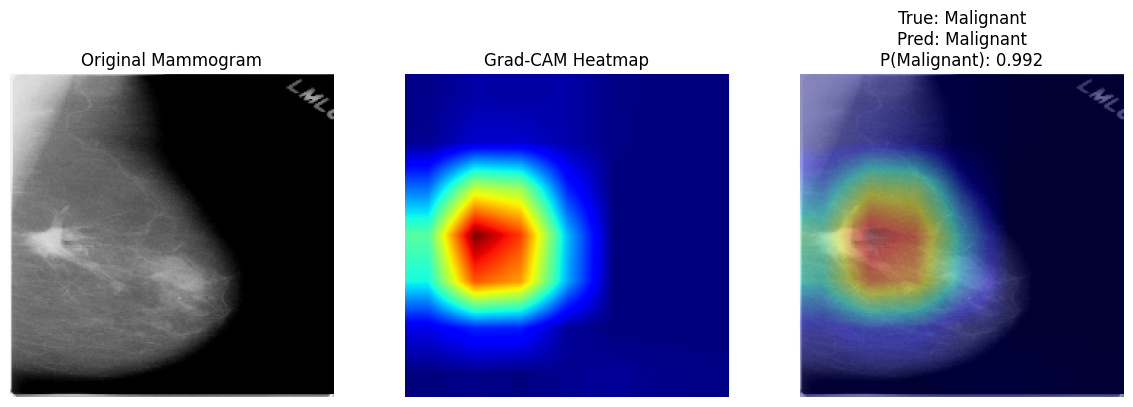

In [ ]:
# True Positive
display_gradcam(
    image_path=test_filepaths[tp_selected],
    true_label='Malignant',
    predicted_label='Malignant',
    probability=error_y_prob[tp_selected]
)

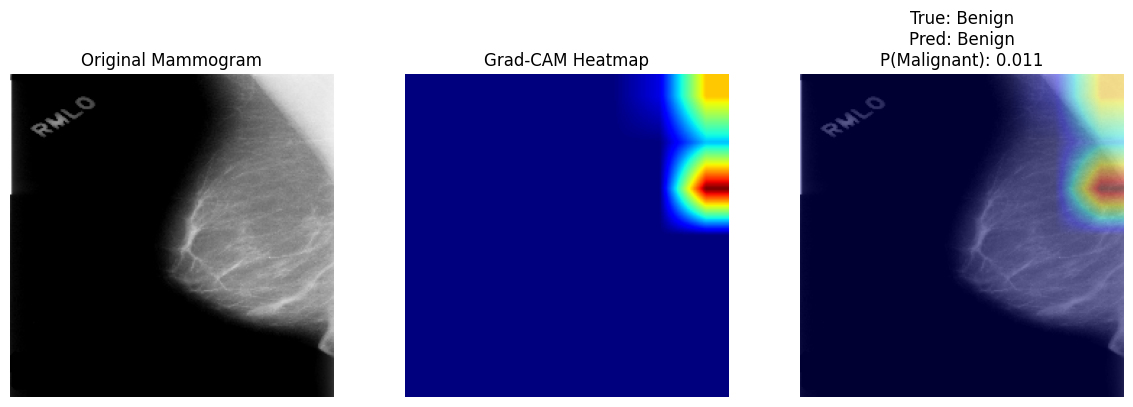

In [ ]:
# True Negative
display_gradcam(
    image_path=test_filepaths[tn_selected],
    true_label='Benign',
    predicted_label='Benign',
    probability=error_y_prob[tn_selected]
)

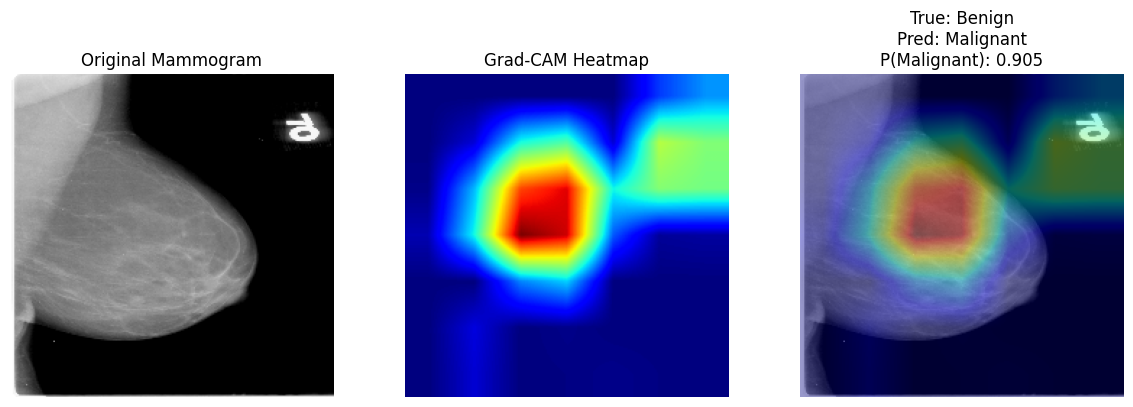

In [ ]:
# False Positive
display_gradcam(
    image_path=test_filepaths[fp_selected],
    true_label='Benign',
    predicted_label='Malignant',
    probability=error_y_prob[fp_selected]
)

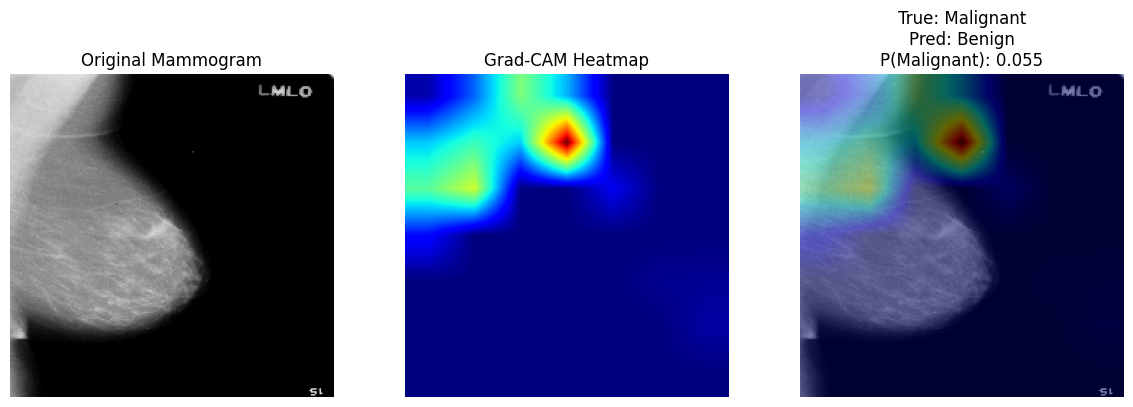

In [ ]:
# False Negative
display_gradcam(
    image_path=test_filepaths[fn_selected],
    true_label='Malignant',
    predicted_label='Benign',
    probability=error_y_prob[fn_selected]
)

Grad-CAM visualisations were generated for representative true-positive, true-negative, false-positive and false-negative predictions from the final fine-tuned ResNet50 model. In some cases, the strongest activation was concentrated within the breast region, indicating that the model used mammographic image content when forming its prediction. However, several examples also showed activation close to image borders and embedded view markers. This suggests that the model may occasionally rely on non-clinical image artefacts or acquisition-related features. The false-positive and false-negative examples further demonstrate that strong activation does not necessarily correspond to a correct prediction. Therefore, Grad-CAM provides useful insight into model behaviour but should not be interpreted as confirming lesion localisation or clinical reasoning.

A limitation of this analysis is that the Grad-CAM regions were not compared with lesion-level ground-truth annotations, so it cannot be determined whether the highlighted regions correspond to the actual abnormality.